In [ ]:

%pip -q install "pymupdf>=1.24" "tiktoken>=0.7" "openai>=1.60" pandas

import os, re, json, time, random, hashlib, getpass
from pathlib import Path
from collections import Counter
import fitz
import tiktoken
import pandas as pd
from openai import (
    OpenAI, RateLimitError, APIConnectionError,
    APITimeoutError, InternalServerError
)

# ---------- Central configuration ----------
FILE_NAME = "24174065_CANADA 2022-23.pdf"
PDF_PATH = Path("/content") / FILE_NAME

# Accept the exact filename or a Colab-uploaded copy with the same prefix.
if not PDF_PATH.is_file():
    matches = sorted(Path("/content").glob("24174065_CANADA 2022-23*.pdf"))
    if not matches:
        raise FileNotFoundError(
            f"Upload {FILE_NAME} to the Colab Files panel first."
        )
    PDF_PATH = matches[0]

OUT = Path("/content/Canada_IMF_Outputs")
CACHE = OUT / "api_cache"
OUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

COUNTRY = "Canada"
REPORT_YEAR = 2023

EXTRACT_MODEL = "gpt-4.1-mini"
JUDGE_MODEL = "gpt-4o-mini"

CHUNK_SIZE = 400
CHUNK_OVERLAP = 50

TOKENIZER = tiktoken.get_encoding("cl100k_base")

def save_json(name, obj):
    path = OUT / name
    temporary = path.with_suffix(".tmp")
    temporary.write_text(
        json.dumps(obj, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )
    temporary.replace(path)

def load_json(name, default):
    path = OUT / name
    if not path.exists():
        return default
    return json.loads(path.read_text(encoding="utf-8"))

def token_count(text):
    return len(TOKENIZER.encode(text))

def word_count(text):
    return len(re.findall(r"\b[\w]+(?:[-'][\w]+)*\b", text))

print("TASK 1 ENVIRONMENT READY")
print("PDF:", PDF_PATH.name)
print("Output:", OUT)
print("Extractor:", EXTRACT_MODEL)
print("Judge:", JUDGE_MODEL)
print("Chunk:", CHUNK_SIZE, "| Overlap:", CHUNK_OVERLAP)


TASK 1 ENVIRONMENT READY
PDF: 24174065_CANADA 2022-23.pdf
Output: /content/Canada_IMF_Outputs
Extractor: gpt-4.1-mini
Judge: gpt-4o-mini
Chunk: 400 | Overlap: 50


In [ ]:

# ---------- PDF extraction and cleaning ----------

def clean_pdf_page(text):
    """Remove recurring report furniture without deleting financial data."""
    lines = []

    for raw in text.replace("\x00", "").splitlines():
        line = raw.strip()

        if not line:
            lines.append("")
            continue

        if line == "CANADA":
            continue

        if re.fullmatch(
            r"(?:\d+\s+)?INTERNATIONAL MONETARY FUND(?:\s+\d+)?",
            line, flags=re.I
        ):
            continue

        if re.fullmatch(r"_{5,}", line):
            continue

        line = re.sub(r"[ \t]+", " ", line)
        lines.append(line)

    result = "\n".join(lines)

    # Rejoin words hyphenated by line wrapping.
    result = re.sub(r"(?<=[A-Za-z])-\n(?=[a-z])", "", result)

    # Preserve paragraph breaks and document headings.
    result = re.sub(r"\n{3,}", "\n\n", result)

    return result.strip()


with fitz.open(str(PDF_PATH)) as doc:
    raw_pages = [page.get_text("text", sort=False) for page in doc]

assert len(raw_pages) == 72, (
    f"Expected 72 pages for this assigned report; found {len(raw_pages)}."
)

pages = [clean_pdf_page(t) for t in raw_pages]

assert sum(len(p) for p in pages) > 70000, (
    "PDF extraction appears incomplete."
)

save_json("task1_clean_pages.json", [
    {"pdf_page": i + 1, "text": text}
    for i, text in enumerate(pages)
])

# ---------- Report-specific section boundaries ----------
# Page numbers refer to physical PDF pages, not printed report pages.
# Markers are verified against the uploaded Canada IMF report.

SECTION_MARKERS = [
    ("Press Release", 2,
     r"IMF Executive Board Concludes 2023 Article IV Consultation"),

    ("Key Issues", 5, r"^KEY ISSUES\s*$"),

    ("Context", 8, r"^CONTEXT\s*$"),

    ("Recent Developments", 9, r"^RECENT DEVELOPMENTS\s*$"),

    ("Outlook and Risks", 16, r"^OUTLOOK AND RISKS\s*$"),

    ("Policy A - Addressing Macroeconomic Imbalances", 19,
     r"^POLICY DISCUSSIONS\s*$"),

    ("Policy B - Safeguarding Financial Stability", 23,
     r"^B\.\s+Safeguarding Financial Stability\s*$"),

    ("Policy C - Structural Challenges and Climate Change", 24,
     r"^C\.\s+Confronting Structural Challenges Including Climate Change\s*$"),

    ("Staff Appraisal", 26, r"^STAFF APPRAISAL\s*$"),

    ("Box 1 - Immigration and Labor Supply", 28,
     r"^Box 1\. Immigration as a Source of Labor Supply in Canada"),

    ("Box 2 - Mortgage Analysis", 29,
     r"^Box 2\. Mortgage Analysis"),

    ("Box 3 - Monetary Policy Transmission", 31,
     r"^Box 3\. Monetary Policy Transmission in Canada"),

    ("Box 4 - Housing and Productivity", 32,
     r"^Box 4\. Housing Booms and Productivity Growth"),

    ("Box 5 - Investment Climate", 33,
     r"^Box 5\. Canada.s Investment Climate"),

    ("Box 6 - Climate Mitigation Policies", 36,
     r"^Box 6\. Canada.s Mitigation Policies"),

    ("Box 7 - Cross-Border Climate Policy Effects", 37,
     r"^Box 7\. Domestic and Cross-Border Effects of Climate Policies in North America"),

    ("Statistical Tables 1-8", 39,
     r"^Table 1\. Canada: Selected Economic Indicators"),

    ("Annex I - Sovereign Risk and Debt Sustainability", 47,
     r"^Annex I\. Sovereign Risk and Debt Sustainability Assessment"),

    ("Annex II - External Sector Assessment", 56,
     r"^Annex II\. External Sector Assessment"),

    ("Annex III - Risk Assessment Matrix", 57,
     r"^Annex III\. Risk Assessment Matrix"),

    ("Annex IV - Previous Policy Recommendations", 59,
     r"^Annex IV\. Progress on Past Article IV Policy Recommendations"),

    ("Annex V - FSAP Recommendations", 60,
     r"^Annex V\. State of Progress in the Implementation of 2019 FSAP"),

    ("Informational Annex", 68,
     r"^STAFF REPORT FOR THE 2023 ARTICLE IV")
]


def find_heading(page_number, pattern):
    text = pages[page_number - 1]
    match = re.search(pattern, text, flags=re.M | re.I)
    if not match:
        raise ValueError(
            f"Missing expected heading on PDF page {page_number}: {pattern}"
        )
    return match.start()


markers = []
for title, page, pattern in SECTION_MARKERS:
    markers.append({
        "title": title,
        "page": page,
        "start": find_heading(page, pattern)
    })


def extract_section(index):
    marker = markers[index]
    first_page = marker["page"]
    first_offset = marker["start"]

    if index + 1 < len(markers):
        next_marker = markers[index + 1]
        last_page = next_marker["page"]
        last_offset = next_marker["start"]
    else:
        last_page = len(pages)
        last_offset = len(pages[-1])

    # The Key Issues section occupies page 5.
    # Pages 6-7 are staff metadata and the table of contents.
    if marker["title"] == "Key Issues":
        last_page = 5
        last_offset = len(pages[4])

    pieces = []

    for page_number in range(first_page, last_page + 1):
        text = pages[page_number - 1]

        if page_number == first_page:
            text = text[first_offset:]

        if page_number == last_page:
            if page_number == first_page:
                text = pages[page_number - 1][first_offset:last_offset]
            else:
                text = text[:last_offset]

        if text.strip():
            pieces.append(f"[PDF PAGE {page_number}]\n{text.strip()}")

    return {
        "id": f"S{index + 1:02d}",
        "title": marker["title"],
        "start_page": first_page,
        "end_page": last_page,
        "text": "\n\n".join(pieces)
    }


sections = [extract_section(i) for i in range(len(markers))]

for section in sections:
    if len(section["text"]) < 150:
        raise ValueError(
            f"Section extraction too short: {section['title']}"
        )

# ---------- Token-aware, overlapping chunking ----------

def chunk_section(section, size=400, overlap=50):
    """Create overlapping token chunks, preferring sentence boundaries."""
    if overlap >= size:
        raise ValueError("Chunk overlap must be smaller than chunk size.")

    tokens = TOKENIZER.encode(section["text"])
    result = []
    start = 0
    index = 0

    while start < len(tokens):
        end = min(start + size, len(tokens))

        # Seek a nearby sentence/paragraph boundary.
        if end < len(tokens):
            candidate = TOKENIZER.decode(tokens[start:end])
            candidates = [
                m.end() for m in re.finditer(
                    r"(?:[.!?]\s+|\n\n)", candidate
                )
            ]

            if candidates:
                desired = candidates[-1]
                aligned = start + len(
                    TOKENIZER.encode(candidate[:desired])
                )

                if aligned - start >= size - 65:
                    end = min(aligned, len(tokens))

        if end <= start:
            end = min(start + size, len(tokens))

        content = TOKENIZER.decode(tokens[start:end])

        result.append({
            "chunk_id": f"{section['id']}_C{index + 1:03d}",
            "section_id": section["id"],
            "section_title": section["title"],
            "start_page": section["start_page"],
            "end_page": section["end_page"],
            "start_token": start,
            "end_token": end,
            "token_count": end - start,
            "text": content
        })

        if end == len(tokens):
            break

        start = end - overlap
        index += 1

    return result


chunks = []
for section in sections:
    chunks.extend(
        chunk_section(section, CHUNK_SIZE, CHUNK_OVERLAP)
    )

assert len(sections) == 23
assert chunks
assert all(c["token_count"] <= CHUNK_SIZE for c in chunks)

save_json("task1_sections.json", sections)
save_json("task1_chunks.json", chunks)

manifest = {
    "country": COUNTRY,
    "report_year": REPORT_YEAR,
    "file_name": PDF_PATH.name,
    "pdf_pages": len(pages),
    "sections": len(sections),
    "chunks": len(chunks),
    "raw_characters": sum(map(len, raw_pages)),
    "clean_characters": sum(map(len, pages)),
    "chunk_size": CHUNK_SIZE,
    "overlap": CHUNK_OVERLAP,
    "extract_model": EXTRACT_MODEL,
    "judge_model": JUDGE_MODEL
}

save_json("task1_manifest.json", manifest)

print("PDF PROCESSING COMPLETE")
print("Pages:", len(pages))
print("Sections:", len(sections))
print("Chunks:", len(chunks))
print("Clean characters:", manifest["clean_characters"])

print("\nSECTION COVERAGE")
for s in sections:
    print(
        s["id"],
        f"Pages {s['start_page']}-{s['end_page']}",
        s["title"],
        "| tokens:", token_count(s["text"])
    )


PDF PROCESSING COMPLETE
Pages: 72
Sections: 23
Chunks: 148
Clean characters: 182468

SECTION COVERAGE
S01 Pages 2-5 Press Release | tokens: 2538
S02 Pages 5-5 Key Issues | tokens: 493
S03 Pages 8-9 Context | tokens: 691
S04 Pages 9-16 Recent Developments | tokens: 2368
S05 Pages 16-19 Outlook and Risks | tokens: 1631
S06 Pages 19-23 Policy A - Addressing Macroeconomic Imbalances | tokens: 2473
S07 Pages 23-24 Policy B - Safeguarding Financial Stability | tokens: 911
S08 Pages 24-26 Policy C - Structural Challenges and Climate Change | tokens: 1234
S09 Pages 26-28 Staff Appraisal | tokens: 724
S10 Pages 28-29 Box 1 - Immigration and Labor Supply | tokens: 734
S11 Pages 29-31 Box 2 - Mortgage Analysis | tokens: 1566
S12 Pages 31-32 Box 3 - Monetary Policy Transmission | tokens: 684
S13 Pages 32-33 Box 4 - Housing and Productivity | tokens: 903
S14 Pages 33-36 Box 5 - Investment Climate | tokens: 1016
S15 Pages 36-37 Box 6 - Climate Mitigation Policies | tokens: 749
S16 Pages 37-39 Box 7 

In [ ]:

# ============================================================
# TASK 1 - CELL 3: GEMINI API, STRUCTURED JSON AND PROMPTS
# ============================================================

%pip -q install -U google-genai

import os, json, time, random, hashlib, getpass
from google import genai
from google.genai import types, errors

# ---------- Lightweight model configuration ----------
EXTRACT_MODEL = "gemini-3.5-flash-lite"
JUDGE_MODEL = "gemini-3.5-flash"

# ---------- Secure Gemini authentication ----------
api_key = None

try:
    from google.colab import userdata
    api_key = userdata.get("Gemini API Key 3")
except Exception:
    pass

if not api_key:
    api_key = getpass.getpass(
        "Enter your Gemini API key (hidden): "
    ).strip()

if not api_key:
    raise ValueError("GEMINI_API_KEY is missing.")

client = genai.Client(api_key=api_key)
del api_key

# ---------- Output schemas ----------
def string_schema(field):
    return {
        "type": "object",
        "properties": {
            field: {"type": "string"}
        },
        "required": [field],
        "additionalProperties": False
    }

SUMMARY_SCHEMA = string_schema("summary")

EXECUTIVE_SCHEMA = {
    "type": "object",
    "properties": {
        "bullets": {
            "type": "array",
            "items": {"type": "string"}
        }
    },
    "required": ["bullets"],
    "additionalProperties": False
}

JUDGE_SCHEMA = {
    "type": "object",
    "properties": {
        "consistency": {"type": "integer", "minimum": 0, "maximum": 5},
        "completeness": {"type": "integer", "minimum": 0, "maximum": 5},
        "factual_alignment": {"type": "integer", "minimum": 0, "maximum": 5},
        "rationale": {"type": "string"},
        "issues": {
            "type": "array",
            "items": {"type": "string"}
        }
    },
    "required": [
        "consistency", "completeness",
        "factual_alignment", "rationale", "issues"
    ],
    "additionalProperties": False
}

# ---------- Retry and caching ----------

# ============================================================
# ROBUST GEMINI STRUCTURED CALL - JSON ERROR FIX
# Replace only the structured_call() function in Cell 3
# ============================================================

def structured_call(model, system, prompt, schema, label,
                    max_tokens=1000):

    import json, hashlib, time, random
    from google.genai import types, errors

    payload = {
        "model": model,
        "system": system,
        "prompt": prompt,
        "schema": schema,
        "max_tokens": max_tokens
    }

    cache_key = hashlib.sha256(
        json.dumps(
            payload,
            sort_keys=True,
            ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    cache_file = CACHE / f"{cache_key}.json"

    def validate_json(data):
        if not isinstance(data, dict):
            raise ValueError("Expected a JSON object.")

        for field in schema.get("required", []):
            if field not in data:
                raise ValueError(f"Missing field: {field}")

        return data

    # ---------- Read cached response safely ----------
    if cache_file.exists():
        try:
            cached = json.loads(
                cache_file.read_text(encoding="utf-8")
            )
            return validate_json(cached)

        except (json.JSONDecodeError, ValueError):
            print(f"Invalid cache detected: {label}")
            cache_file.unlink(missing_ok=True)

    # ---------- API request with automatic retries ----------
    last_error = None

    for attempt in range(7):
        try:
            response = client.models.generate_content(
                model=model,
                contents=prompt,
                config=types.GenerateContentConfig(
                    system_instruction=system,
                    response_mime_type="application/json",
                    response_json_schema=schema,
                    temperature=0,
                    max_output_tokens=max(1800, max_tokens),
                    http_options=types.HttpOptions(
                        timeout=120000
                    )
                )
            )

            raw_text = response.text

            if not raw_text or not raw_text.strip():
                raise ValueError("Gemini returned an empty response.")

            # ---------- Parse and validate JSON ----------
            try:
                result = json.loads(raw_text)

            except json.JSONDecodeError as exc:
                print(
                    f"Malformed Gemini JSON for {label}. "
                    f"Retry {attempt + 1}/7."
                )
                raise ValueError(
                    f"Gemini response was not valid JSON: {exc}"
                ) from exc

            result = validate_json(result)

            # ---------- Validate judge scores ----------
            if all(
                key in result for key in [
                    "consistency",
                    "completeness",
                    "factual_alignment"
                ]
            ):
                for key in [
                    "consistency",
                    "completeness",
                    "factual_alignment"
                ]:
                    score = result[key]

                    if type(score) is not int or not 0 <= score <= 5:
                        raise ValueError(
                            f"Invalid {key} score: {score}"
                        )

            # ---------- Save successful response ----------
            temp_file = cache_file.with_suffix(".tmp")

            temp_file.write_text(
                json.dumps(
                    result,
                    ensure_ascii=False,
                    indent=2
                ),
                encoding="utf-8"
            )

            temp_file.replace(cache_file)

            return result

        except errors.APIError as exc:
            last_error = exc
            status = getattr(exc, "code", None)

            # Never retry invalid API keys, model IDs, or permissions.
            if status not in (429, 500, 502, 503, 504):
                raise RuntimeError(
                    f"Non-retryable Gemini API error "
                    f"{status}: {exc}"
                ) from exc

            delay = min(
                90,
                2 ** (attempt + 2) + random.uniform(1, 4)
            )

            print(
                f"Temporary Gemini API error {status}. "
                f"Retrying in {delay:.1f}s."
            )

            if attempt < 6:
                time.sleep(delay)

        except (ValueError, json.JSONDecodeError) as exc:
            last_error = exc

            if attempt < 6:
                delay = min(12, 2 + attempt * 2)
                time.sleep(delay)

    raise RuntimeError(
        f"Failed to obtain valid structured JSON "
        f"for {label} after 7 attempts. "
        f"Last error: {last_error}"
    )


# ---------- Summarization prompts ----------
SUMMARY_SYSTEM = """
You are a specialist IMF macroeconomic research analyst.

Summarize the supplied IMF report section accurately.

Rules:
1. Use only supplied document evidence.
2. Preserve the 2023 historical reporting perspective.
3. Distinguish actual observations from projections.
4. Identify important financial stability findings.
5. Preserve major economic risks and IMF recommendations.
6. Never invent numbers, dates or unsupported conclusions.
7. Keep each summary strictly below 100 words.
8. Use concise, neutral, professional language.
"""

SUMMARY_PROMPT = """
Country: Canada
Report: IMF 2023 Article IV Consultation
Section: {title}
PDF pages: {start_page}-{end_page}

Summarize this section in 65-90 words.

Prioritize the section's principal findings, economic
evidence, vulnerabilities and policy recommendations.

For financial tables, describe only trends supported
by clearly identifiable figures.

SOURCE DOCUMENT:
{text}
"""

# ---------- Independent evaluation prompts ----------
JUDGE_SYSTEM = """
You are an independent IMF quality evaluator.

Audit the supplied summary against its source text.

Assess three independent dimensions, each on a 0-5 scale.

CONSISTENCY:
Internal coherence, terminology and lack of contradictions.

COMPLETENESS:
Coverage of the main economic findings, vulnerabilities
and important policy recommendations.

FACTUAL ALIGNMENT:
Accuracy of numbers, dates, economic claims and source support.

Score critically. Do not automatically award high marks.
Penalize hallucinations, wrong periods, incorrect numerical
statements and important omissions.

Provide:
- Three integer scores
- A concise evidence-based rationale
- A list of specific issues, empty when none exist

Do not introduce outside knowledge.
"""

JUDGE_PROMPT = """
Evaluate the following IMF section summary.

Section: {title}
PDF pages: {start_page}-{end_page}

ORIGINAL SOURCE:
{source}

GENERATED SUMMARY:
{summary}

Judge consistency, completeness and factual alignment
independently using the provided source.
"""

# ---------- Executive summary prompts ----------
EXECUTIVE_SYSTEM = """
You are an IMF financial stability analyst.

Create concise executive-level findings for the Canada
2023 Article IV Consultation.

All claims must be grounded in the provided evidence.
Maintain the original report's 2023 perspective.
Distinguish forecasts from actual outcomes.
Avoid invented statistics, repetition and speculation.
"""

EXECUTIVE_PROMPT = """
Generate exactly seven executive-summary bullets
from the following report-wide evidence.

Cover:
1. Growth and inflation
2. Monetary and fiscal policy
3. Banking system resilience
4. Housing and household debt
5. Systemic and external risks
6. Structural and productivity challenges
7. Main IMF policy recommendations

SECTION SUMMARIES:
{section_summaries}

ORIGINAL SOURCE EXCERPTS:
{primary_evidence}
"""

# ---------- Save prompt documentation ----------
save_json("task1_prompt_templates.json", {
    "summary_system": SUMMARY_SYSTEM,
    "summary_prompt": SUMMARY_PROMPT,
    "judge_system": JUDGE_SYSTEM,
    "judge_prompt": JUDGE_PROMPT,
    "executive_system": EXECUTIVE_SYSTEM,
    "executive_prompt": EXECUTIVE_PROMPT,
    "models": {
        "extractor": EXTRACT_MODEL,
        "evaluator": JUDGE_MODEL
    }
})

# Update manifest from Cell 2 to reflect Gemini.
manifest = load_json("task1_manifest.json", {})
manifest["extract_model"] = EXTRACT_MODEL
manifest["judge_model"] = JUDGE_MODEL
save_json("task1_manifest.json", manifest)

# ---------- Lightweight authentication test ----------
print("Testing Gemini connection...")

test = structured_call(
    model=EXTRACT_MODEL,
    system="Return a valid JSON object.",
    prompt="Return the word Canada as the summary.",
    schema=SUMMARY_SCHEMA,
    label="gemini_connection_test",
    max_tokens=100
)

assert test["summary"].strip().lower() == "canada"

print("\nGEMINI API CONNECTED SUCCESSFULLY")
print("Summarization model:", EXTRACT_MODEL)
print("Evaluation model:", JUDGE_MODEL)
print("Structured JSON: Enabled")
print("Disk caching: Enabled")
print("Task 1 ready for Cell 4")


Enter your Gemini API key (hidden): ··········
Testing Gemini connection...

GEMINI API CONNECTED SUCCESSFULLY
Summarization model: gemini-3.5-flash-lite
Evaluation model: gemini-3.5-flash
Structured JSON: Enabled
Disk caching: Enabled
Task 1 ready for Cell 4


In [ ]:


import re
import pandas as pd

# ---------- Load previously completed summaries ----------
summaries = load_json("task1_summaries.json", {})

def generate_section_summary(section):
    """
    Generate a factual IMF section summary under 100 words.
    Automatically repair excessive word counts while preserving
    key findings, economic indicators, and financial risks.
    """

    prompt = SUMMARY_PROMPT.format(
        title=section["title"],
        start_page=section["start_page"],
        end_page=section["end_page"],
        text=section["text"]
    )

    # Step 1: Generate original section summary
    result = structured_call(
        model=EXTRACT_MODEL,
        system=SUMMARY_SYSTEM,
        prompt=prompt,
        schema=SUMMARY_SCHEMA,
        label="section_summary",
        max_tokens=500
    )

    summary = result["summary"].strip()

    # Step 2: Automatically repair overlength summaries
    # Use progressively stricter limits to ensure compliance.
    for target in [75, 60, 45]:

        if summary and word_count(summary) < 100:
            break

        repair_prompt = f"""
Rewrite the following IMF section summary in STRICTLY
FEWER THAN {target} WORDS.

Requirements:
- Preserve the principal macroeconomic findings.
- Retain important numerical evidence.
- Include material financial stability risks.
- Preserve important IMF policy recommendations.
- Do not introduce new facts or statistics.
- Use concise, professional academic language.
- Return JSON containing only the field "summary".

SECTION:
{section['title']}

ORIGINAL SUMMARY:
{summary}
"""

        repaired = structured_call(
            model=EXTRACT_MODEL,
            system=SUMMARY_SYSTEM,
            prompt=repair_prompt,
            schema=SUMMARY_SCHEMA,
            label=f"summary_repair_{target}",
            max_tokens=350
        )

        summary = repaired["summary"].strip()

    # Step 3: Deterministic word-limit protection
    if word_count(summary) >= 100:

        sentences = re.split(
            r"(?<=[.!?])\s+",
            summary
        )

        retained = []

        for sentence in sentences:
            candidate = " ".join(retained + [sentence])

            if word_count(candidate) >= 100:
                break

            retained.append(sentence)

        summary = " ".join(retained).strip()

        # Handle unusually long single sentences.
        if not summary:
            words = re.findall(r"\S+", result["summary"])
            summary = " ".join(words[:85]).strip()

    # Step 4: Final validation
    total_words = word_count(summary)

    if not summary or total_words >= 100:
        raise ValueError(
            f"Summary constraint failed: {section['title']} "
            f"({total_words} words)"
        )

    return {
        "section_id": section["id"],
        "title": section["title"],
        "start_page": section["start_page"],
        "end_page": section["end_page"],
        "summary": summary,
        "word_count": total_words,
        "model": EXTRACT_MODEL
    }


# ---------- Generate summaries with checkpointing ----------

print("=" * 70)
print("TASK 1 - CANADA IMF SECTION SUMMARISATION")
print("=" * 70)

print(f"Total sections: {len(sections)}")
print(f"Previously saved: {len(summaries)}")
print(f"Summarization model: {EXTRACT_MODEL}")
print("-" * 70)

for index, section in enumerate(sections, start=1):

    sid = section["id"]

    # Reuse valid previously saved summaries.
    existing = summaries.get(sid)

    reusable = (
        isinstance(existing, dict)
        and isinstance(existing.get("summary"), str)
        and 0 < word_count(existing["summary"]) < 100
        and existing.get("model") == EXTRACT_MODEL
    )

    if reusable:
        item = existing
        status = "CACHED"

    else:
        item = generate_section_summary(section)

        # Immediately save successful results.
        summaries[sid] = item
        save_json("task1_summaries.json", summaries)

        status = "GENERATED"

    print(
        f"[{index:02d}/{len(sections)}] "
        f"{section['title']} | "
        f"{word_count(item['summary'])} words | {status}"
    )


# ---------- Final completeness and word-limit checks ----------

expected_ids = {section["id"] for section in sections}

completed_ids = set(summaries.keys())

missing_ids = expected_ids - completed_ids

if missing_ids:
    raise ValueError(
        f"Missing section summaries: {sorted(missing_ids)}"
    )

invalid_sections = [
    item["title"]
    for item in summaries.values()
    if not (0 < word_count(item["summary"]) < 100)
]

if invalid_sections:
    raise ValueError(
        f"Word-limit violations: {invalid_sections}"
    )


# ---------- Export structured summary results ----------

summary_rows = []

for section in sections:

    item = summaries[section["id"]]

    summary_rows.append({
        "section_id": item["section_id"],
        "section": item["title"],
        "start_page": item["start_page"],
        "end_page": item["end_page"],
        "word_count": word_count(item["summary"]),
        "summary": item["summary"],
        "model": item["model"]
    })

df_summaries = pd.DataFrame(summary_rows)

df_summaries.to_csv(
    OUT / "task1_section_summaries.csv",
    index=False,
    encoding="utf-8"
)


# ---------- Create readable text report ----------

with open(
    OUT / "task1_section_summaries.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "CANADA - IMF 2023 ARTICLE IV CONSULTATION\n"
    )

    file.write(
        "TASK 1: SECTION SUMMARIES\n"
    )

    file.write("=" * 65 + "\n\n")

    for _, row in df_summaries.iterrows():

        file.write(
            f"SECTION: {row['section']}\n"
        )

        file.write(
            f"PDF PAGES: "
            f"{row['start_page']}-{row['end_page']}\n"
        )

        file.write(
            f"WORD COUNT: {row['word_count']}\n\n"
        )

        file.write(
            row["summary"] + "\n\n"
        )

        file.write("-" * 65 + "\n\n")


# ---------- Save validation results ----------

summary_validation = {
    "country": COUNTRY,
    "report_year": REPORT_YEAR,
    "pdf_file": PDF_PATH.name,
    "model": EXTRACT_MODEL,
    "total_sections": len(sections),
    "completed_sections": len(summary_rows),
    "all_under_100_words": all(
        row["word_count"] < 100
        for row in summary_rows
    ),
    "average_summary_words": round(
        df_summaries["word_count"].mean(), 2
    ),
    "minimum_summary_words": int(
        df_summaries["word_count"].min()
    ),
    "maximum_summary_words": int(
        df_summaries["word_count"].max()
    )
}

save_json(
    "task1_summary_validation.json",
    summary_validation
)


# ---------- Final output ----------

print("\n" + "=" * 70)
print("TASK 1 - SECTION SUMMARISATION COMPLETED")
print("=" * 70)

print("Total sections:", len(sections))
print("Summaries generated:", len(summary_rows))

print(
    "All summaries under 100 words:",
    "PASS" if summary_validation["all_under_100_words"]
    else "FAIL"
)

print(
    "Average words per summary:",
    summary_validation["average_summary_words"]
)

print(
    "Longest summary:",
    summary_validation["maximum_summary_words"],
    "words"
)

print("\nOutput files:")
print("- task1_summaries.json")
print("- task1_section_summaries.csv")
print("- task1_section_summaries.txt")
print("- task1_summary_validation.json")

print("\nREADY FOR CELL 5: LLM-AS-A-JUDGE EVALUATION")


TASK 1 - CANADA IMF SECTION SUMMARISATION
Total sections: 23
Previously saved: 23
Summarization model: gemini-3.5-flash-lite
----------------------------------------------------------------------
[01/23] Press Release | 83 words | CACHED
[02/23] Key Issues | 84 words | CACHED
[03/23] Context | 70 words | CACHED
[04/23] Recent Developments | 91 words | CACHED
[05/23] Outlook and Risks | 93 words | CACHED
[06/23] Policy A - Addressing Macroeconomic Imbalances | 85 words | CACHED
[07/23] Policy B - Safeguarding Financial Stability | 86 words | CACHED
[08/23] Policy C - Structural Challenges and Climate Change | 90 words | CACHED
[09/23] Staff Appraisal | 88 words | CACHED
[10/23] Box 1 - Immigration and Labor Supply | 91 words | CACHED
[11/23] Box 2 - Mortgage Analysis | 96 words | CACHED
[12/23] Box 3 - Monetary Policy Transmission | 90 words | CACHED
[13/23] Box 4 - Housing and Productivity | 84 words | CACHED
[14/23] Box 5 - Investment Climate | 73 words | CACHED
[15/23] Box 6 - Climat

In [ ]:

# ---------- Independent LLM-as-a-Judge evaluation ----------


# ---------- Gemini API rate-limit protection ----------
import time

# Preserve the original API function only once.
if "_original_structured_call" not in globals():
    _original_structured_call = structured_call

_last_api_call = {}

def structured_call(model, system, prompt, schema, label,
                    max_tokens=1000):

    # Use a conservative interval for each model.
    if model == JUDGE_MODEL:
        interval = 21.0  # About 2.85 requests/minute
    else:
        interval = 8.0   # About 7.5 requests/minute

    now = time.monotonic()
    last = _last_api_call.get(model)

    if last is not None:
        remaining = interval - (now - last)
        if remaining > 0:
            print(f"API pacing: {remaining:.1f}s")
            time.sleep(remaining)

    _last_api_call[model] = time.monotonic()

    return _original_structured_call(
        model=model,
        system=system,
        prompt=prompt,
        schema=schema,
        label=label,
        max_tokens=max_tokens
    )

print("Gemini API pacing enabled.")

evaluations = load_json("task1_evaluations.json", {})

def evaluate_summary(section, summary_item):
    prompt = JUDGE_PROMPT.format(
        title=section["title"],
        start_page=section["start_page"],
        end_page=section["end_page"],
        source=section["text"],
        summary=summary_item["summary"]
    )

    result = structured_call(
        model=JUDGE_MODEL,
        system=JUDGE_SYSTEM,
        prompt=prompt,
        schema=JUDGE_SCHEMA,
        label="summary_audit",
        max_tokens=650
    )

    dimensions = [
        "consistency",
        "completeness",
        "factual_alignment"
    ]

    for dimension in dimensions:
        score = result[dimension]
        if type(score) is not int or not 0 <= score <= 5:
            raise ValueError(
                f"Invalid judge score for {dimension}: {score}"
            )

    mean_score = round(
        sum(result[d] for d in dimensions) / 3, 2
    )

    return {
        "section_id": section["id"],
        "title": section["title"],
        "consistency": result["consistency"],
        "completeness": result["completeness"],
        "factual_alignment": result["factual_alignment"],
        "mean_score": mean_score,
        "rationale": result["rationale"],
        "issues": result["issues"],
        "judge_model": JUDGE_MODEL
    }


print("RUNNING INDEPENDENT SECTION AUDITS")
print("=" * 65)

for index, section in enumerate(sections, start=1):
    sid = section["id"]

    if sid not in evaluations:
        evaluations[sid] = evaluate_summary(
            section, summaries[sid]
        )
        save_json("task1_evaluations.json", evaluations)

    result = evaluations[sid]

    print(
        f"[{index:02d}/{len(sections)}] "
        f"{result['title'][:36]:36} "
        f"C={result['consistency']} "
        f"Complete={result['completeness']} "
        f"Factual={result['factual_alignment']} "
        f"Mean={result['mean_score']:.2f}/5"
    )

assert len(evaluations) == len(sections)

# ---------- Seven-bullet report-wide executive summary ----------

executive_path = OUT / "task1_executive_summary.json"

if executive_path.exists():
    executive = load_json(
        "task1_executive_summary.json", {}
    )
else:
    summary_evidence = "\n\n".join(
        f"{s['title']}: {summaries[s['id']]['summary']}"
        for s in sections
    )

    # Include the original IMF findings to supplement the
    # section summaries with primary-source evidence.
    focus_titles = [
        "Press Release",
        "Key Issues",
        "Outlook and Risks",
        "Policy B - Safeguarding Financial Stability",
        "Staff Appraisal"
    ]

    primary_evidence = "\n\n".join(
        f"{s['title']}:\n{s['text'][:4500]}"
        for s in sections
        if s["title"] in focus_titles
    )

    executive_prompt = EXECUTIVE_PROMPT.format(
        section_summaries=summary_evidence,
        primary_evidence=primary_evidence
    )

    executive = structured_call(
        model=EXTRACT_MODEL,
        system=EXECUTIVE_SYSTEM,
        prompt=executive_prompt,
        schema=EXECUTIVE_SCHEMA,
        label="executive_summary",
        max_tokens=1100
    )

    if len(executive["bullets"]) != 7:
        raise ValueError(
            "Executive summary must contain exactly seven bullets."
        )

    save_json("task1_executive_summary.json", executive)

# ---------- Evaluate executive summary ----------

executive_text = "\n".join(
    f"- {bullet}" for bullet in executive["bullets"]
)

executive_source = "\n\n".join(
    f"{s['title']}:\n{summaries[s['id']]['summary']}"
    for s in sections
)

# Add key original source material for factual checking.
executive_source += "\n\nORIGINAL IMF SOURCE EXCERPTS:\n"
executive_source += "\n\n".join(
    s["text"][:4500] for s in sections
    if s["title"] in [
        "Press Release", "Key Issues",
        "Outlook and Risks", "Staff Appraisal"
    ]
)

executive_audit_file = OUT / "task1_executive_audit.json"

if executive_audit_file.exists():
    executive_audit = load_json(
        "task1_executive_audit.json", {}
    )
else:
    executive_audit = structured_call(
        model=JUDGE_MODEL,
        system=JUDGE_SYSTEM,
        prompt=JUDGE_PROMPT.format(
            title="Full Report Executive Summary",
            start_page=1,
            end_page=72,
            source=executive_source,
            summary=executive_text
        ),
        schema=JUDGE_SCHEMA,
        label="executive_audit",
        max_tokens=800
    )

    for dimension in [
        "consistency", "completeness", "factual_alignment"
    ]:
        if not isinstance(executive_audit[dimension], int):
            raise ValueError("Invalid executive audit score.")
        if not 0 <= executive_audit[dimension] <= 5:
            raise ValueError("Executive audit score outside 0-5.")

    save_json("task1_executive_audit.json", executive_audit)

# ---------- Produce evaluation tables ----------

evaluation_rows = [
    {
        "section": result["title"],
        "consistency": result["consistency"],
        "completeness": result["completeness"],
        "factual_alignment": result["factual_alignment"],
        "mean_score": result["mean_score"],
        "issues": "; ".join(result["issues"])
    }
    for result in evaluations.values()
]

df_scores = pd.DataFrame(evaluation_rows)

df_scores.to_csv(
    OUT / "task1_evaluation_scores.csv",
    index=False
)

mean_scores = {
    dimension: round(
        df_scores[dimension].mean(), 2
    )
    for dimension in [
        "consistency", "completeness",
        "factual_alignment", "mean_score"
    ]
}

validation = {
    "country": COUNTRY,
    "report": PDF_PATH.name,
    "pdf_pages": len(pages),
    "total_sections": len(sections),
    "sections_summarized": len(summaries),
    "sections_evaluated": len(evaluations),
    "all_summaries_under_100_words": all(
        0 < item["word_count"] < 100
        for item in summaries.values()
    ),
    "executive_bullet_count": len(executive["bullets"]),
    "average_judge_scores": mean_scores,
    "executive_judge_scores": executive_audit,
    "models": {
        "extractor": EXTRACT_MODEL,
        "judge": JUDGE_MODEL
    }
}

save_json("task1_validation.json", validation)

# ---------- Human-readable results ----------

with open(
    OUT / "task1_executive_summary.txt",
    "w", encoding="utf-8"
) as f:
    f.write("CANADA - IMF 2023 ARTICLE IV CONSULTATION\n")
    f.write("TASK 1 EXECUTIVE SUMMARY\n\n")
    f.write(executive_text)
    f.write("\n\nEXECUTIVE AUDIT\n")
    f.write(json.dumps(
        executive_audit, ensure_ascii=False, indent=2
    ))

# ---------- Final checks ----------

assert validation["sections_summarized"] == 23
assert validation["sections_evaluated"] == 23
assert validation["all_summaries_under_100_words"]
assert validation["executive_bullet_count"] == 7

print("\n" + "=" * 65)
print("TASK 1 - FINAL RESULTS")
print("=" * 65)

print("\nEXECUTIVE SUMMARY")
print(executive_text)

print("\nAVERAGE SECTION EVALUATION")
for dimension, score in mean_scores.items():
    print(f"{dimension}: {score:.2f}/5")

print("\nEXECUTIVE AUDIT")
for dimension in [
    "consistency", "completeness", "factual_alignment"
]:
    print(f"{dimension}: {executive_audit[dimension]}/5")

print("\nSECTION-LEVEL EVALUATION TABLE")
print(
    df_scores[
        ["section", "consistency", "completeness",
         "factual_alignment", "mean_score"]
    ].to_string(index=False)
)

print("\nVALIDATION")
print("Sections summarized:", len(summaries))
print("Sections audited:", len(evaluations))
print("Executive bullets:", len(executive["bullets"]))
print("Word limits:", "PASS")

# ---------- Package results for subsequent tasks ----------
import shutil

archive = shutil.make_archive(
    "/content/Canada_Task1_Outputs",
    "zip",
    root_dir=OUT
)

print("\nTASK 1 COMPLETED")
print("Outputs directory:", OUT)
print("ZIP archive:", archive)


Gemini API pacing enabled.
RUNNING INDEPENDENT SECTION AUDITS
[01/23] Press Release                        C=5 Complete=5 Factual=5 Mean=5.00/5
[02/23] Key Issues                           C=5 Complete=4 Factual=5 Mean=4.67/5
[03/23] Context                              C=5 Complete=4 Factual=5 Mean=4.67/5
[04/23] Recent Developments                  C=5 Complete=5 Factual=5 Mean=5.00/5
[05/23] Outlook and Risks                    C=5 Complete=4 Factual=5 Mean=4.67/5
[06/23] Policy A - Addressing Macroeconomic  C=5 Complete=4 Factual=5 Mean=4.67/5
[07/23] Policy B - Safeguarding Financial St C=5 Complete=4 Factual=4 Mean=4.33/5
[08/23] Policy C - Structural Challenges and C=5 Complete=5 Factual=5 Mean=5.00/5
[09/23] Staff Appraisal                      C=5 Complete=4 Factual=5 Mean=4.67/5
[10/23] Box 1 - Immigration and Labor Supply C=5 Complete=5 Factual=5 Mean=5.00/5
[11/23] Box 2 - Mortgage Analysis            C=5 Complete=4 Factual=5 Mean=4.67/5
[12/23] Box 3 - Monetary Policy Tran

In [ ]:

# ============================================================
# TASK 2: SEVEN-THEME FINANCIAL STABILITY SCANNING
# ============================================================

import re
import json
import pandas as pd
from collections import defaultdict

# Use Task 1's original cleaned pages, not overlapping chunks.
# This prevents chunk overlap from inflating thematic counts.
clean_pages = load_json("task1_clean_pages.json", [])

if len(clean_pages) != 72:
    raise ValueError("Task 1 cleaned pages are missing or incomplete.")

THEMES = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bdisinflation\b",
        r"\bconsumer prices?\b", r"\bCPI\b",
        r"\bprice stability\b", r"\binflation expectations?\b",
        r"\bprice pressures?\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bpolicy rates?\b",
        r"\bcredit growth\b", r"\bcredit conditions?\b",
        r"\bmonetary tightening\b", r"\blending rates?\b",
        r"\bborrowing costs?\b", r"\bmonetary policy\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\bhouse prices?\b",
        r"\bmortgages?\b", r"\breal estate\b",
        r"\bproperty prices?\b", r"\brents?\b",
        r"\bhousing affordability\b", r"\bCRE\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bbank capital\b", r"\bcapital adequacy\b",
        r"\bcapital requirements?\b", r"\bcapital buffers?\b",
        r"\bliquidity\b", r"\bliquid assets?\b",
        r"\bTier 1\b", r"\bCET1\b",
        r"\bbank funding\b", r"\bdeposit outflows?\b"
    ],
    "Sovereign Debt": [
        r"\bsovereign debt\b", r"\bpublic debt\b",
        r"\bgovernment debt\b", r"\bfederal debt\b",
        r"\bfiscal deficit\b", r"\bdebt sustainability\b",
        r"\bfiscal consolidation\b", r"\bdebt anchor\b",
        r"\bfiscal buffers?\b"
    ],
    "Labor Market Dynamics": [
        r"\blabou?r markets?\b", r"\bunemployment\b",
        r"\bemployment\b", r"\bwage growth\b",
        r"\blabou?r force\b", r"\bjob vacancies\b",
        r"\bimmigration\b", r"\bproductivity\b",
        r"\blabou?r participation\b"
    ],
    "Systemic Financial Risk": [
        r"\bfinancial stability\b", r"\bsystemic risks?\b",
        r"\bfinancial stress\b", r"\bcontagion\b",
        r"\bstress tests?\b", r"\bfinancial vulnerabilities\b",
        r"\bNBFIs?\b", r"\bnonbank financial\b",
        r"\bfinancial distress\b", r"\bbanking turmoil\b"
    ]
}

compiled_themes = {
    name: [re.compile(p, re.I) for p in patterns]
    for name, patterns in THEMES.items()
}

# Scan the principal analytical report and risk annexes.
# Exclude the duplicated press release, contents pages,
# densely formatted statistical tables and informational annex.
SCAN_PAGES = list(range(8, 39)) + list(range(47, 68))

def narrative_passages(text):
    """Normalize lines and split into approximately sentence units."""
    text = re.sub(r"\[PDF PAGE \d+\]", " ", text)
    text = re.sub(r"(?<=\w)-\s*\n\s*(?=[a-z])", "", text)
    text = re.sub(r"\s*\n\s*", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return [
        sentence.strip()
        for sentence in re.split(r"(?<=[.!?])\s+", text)
        if len(sentence.strip()) >= 25
    ]

counts = {theme: 0 for theme in THEMES}
evidence = {theme: [] for theme in THEMES}
page_distribution = defaultdict(lambda: defaultdict(int))
passages_scanned = 0

for page in clean_pages:
    page_no = page["pdf_page"]

    if page_no not in SCAN_PAGES:
        continue

    for passage in narrative_passages(page["text"]):
        passages_scanned += 1

        for theme, patterns in compiled_themes.items():
            matched = [
                p.pattern for p in patterns if p.search(passage)
            ]

            if matched:
                counts[theme] += 1
                page_distribution[theme][page_no] += 1

                evidence[theme].append({
                    "pdf_page": page_no,
                    "text": passage,
                    "matched_patterns": matched
                })

total_mentions = sum(counts.values())

theme_distribution = [
    {
        "theme": theme,
        "count": count,
        "percentage": round(
            100 * count / total_mentions, 2
        ) if total_mentions else 0.0,
        "pages_with_mentions": len(page_distribution[theme])
    }
    for theme, count in counts.items()
]

assert len(theme_distribution) == 7
assert total_mentions > 0

save_json("task2_theme_counts.json", {
    "country": COUNTRY,
    "method": "Sentence-level thematic keyword and phrase matches",
    "count_unit": "passage-theme matches",
    "overlapping_chunks_excluded": True,
    "multiple_themes_per_passage_allowed": True,
    "pdf_pages_scanned": SCAN_PAGES,
    "passages_scanned": passages_scanned,
    "total_theme_mentions": total_mentions,
    "distribution": theme_distribution
})

save_json("task2_theme_evidence.json", evidence)

df_themes = pd.DataFrame(theme_distribution)
df_themes.to_csv(OUT / "task2_theme_counts.csv", index=False)

print("=" * 65)
print("TASK 2 - THEMATIC DISTRIBUTION")
print("=" * 65)
print(df_themes.to_string(index=False))
print("\nTotal thematic mentions:", total_mentions)
print("Passages scanned:", passages_scanned)
print("Seven financial themes: PASS")


TASK 2 - THEMATIC DISTRIBUTION
                      theme  count  percentage  pages_with_mentions
         Inflation & Prices     52       15.12                   21
    Interest Rates & Credit     57       16.57                   23
      Housing & Real Estate     92       26.74                   26
Banking Capital & Liquidity     25        7.27                   16
             Sovereign Debt     33        9.59                   16
      Labor Market Dynamics     53       15.41                   19
    Systemic Financial Risk     32        9.30                   15

Total thematic mentions: 344
Passages scanned: 789
Seven financial themes: PASS


In [ ]:

# ============================================================
# TASK 2: INDICATORS, FALLBACKS AND TEMPORAL TRENDS
# ============================================================

import fitz
import re
import math
import pandas as pd

with fitz.open(str(PDF_PATH)) as pdf:
    # sort=True improves extraction of row-oriented IMF tables.
    source_pages = {
        n: pdf[n - 1].get_text("text", sort=True)
        for n in [11, 14, 39, 43]
    }

NUM_PATTERN = re.compile(
    r"(?<![\w/])-?\d+(?:,\d{3})*(?:\.\d+)?(?![\w/])"
)

def parse_numbers(text):
    return [
        float(m.group().replace(",", ""))
        for m in NUM_PATTERN.finditer(text)
    ]

def extract_table_row(page, label, years):
    """Read a named row and enforce the expected number of year columns."""
    candidates = []

    for line in source_pages[page].splitlines():
        match = re.match(
            r"^\s*" + re.escape(label) + r"(?=\s|$)",
            line, flags=re.I
        )
        if match:
            candidates.append(line[match.end():])

    if len(candidates) != 1:
        raise ValueError(
            f"Expected one '{label}' row on PDF page {page}; "
            f"found {len(candidates)}."
        )

    values = parse_numbers(candidates[0])

    if len(values) != len(years):
        raise ValueError(
            f"{label}: expected {len(years)} values, got "
            f"{len(values)}. Check PDF table extraction."
        )

    return {
        "label": label,
        "pdf_page": page,
        "years": years,
        "values": values,
        "source_text": candidates[0].strip()
    }


YEARS_2020_2028 = list(range(2020, 2029))
YEARS_2014_2022 = list(range(2014, 2023))

TABLE_ROWS = {
    "real_gdp_growth_pct": extract_table_row(
        39, "Real GDP", YEARS_2020_2028
    ),
    "cpi_inflation_annual_average_pct": extract_table_row(
        39, "CPI inflation (average)", YEARS_2020_2028
    ),
    "unemployment_annual_average_pct": extract_table_row(
        39, "Unemployment rate (average) 2/", YEARS_2020_2028
    ),
    "household_credit_growth_pct": extract_table_row(
        39, "Household Credit Growth", YEARS_2020_2028
    ),
    "business_credit_growth_pct": extract_table_row(
        39, "Business Credit Growth", YEARS_2020_2028
    ),
    "general_government_gross_debt_pct_gdp": extract_table_row(
        39, "Gross Debt", YEARS_2020_2028
    ),
    "tier_1_capital_ratio_pct": extract_table_row(
        43, "Tier 1 ratio", YEARS_2014_2022
    ),
    "npl_to_gross_loans_pct": extract_table_row(
        43, "NPLs to Gross Loans", YEARS_2014_2022
    )
}

# Locate the relevant narrative observations.
inflation_match = re.search(
    r"Headline inflation fell[\s\S]{0,220}?"
    r"to\s+(\d+(?:\.\d+)?)\s+percent\s+in May",
    source_pages[11], re.I
)

policy_match = re.search(
    r"taking it to\s+(\d+(?:\.\d+)?)\s+percent",
    source_pages[14], re.I
)

def row_value(row_key, year):
    row = TABLE_ROWS[row_key]
    if year not in row["years"]:
        return None
    return float(row["values"][row["years"].index(year)])

# Required schema: one string field plus six float-or-null fields.
indicator_specs = {
    "gdp_growth_forecast_pct": {
        "value": row_value("real_gdp_growth_pct", 2023),
        "period": "2023 annual forecast",
        "pdf_page": 39,
        "source": "Table 1: Real GDP"
    },
    "headline_inflation_rate_pct": {
        "value": float(inflation_match.group(1))
                 if inflation_match else None,
        "period": "May 2023, year-on-year",
        "pdf_page": 11,
        "source": "Recent Developments: headline inflation"
    },
    "central_bank_policy_rate_pct": {
        "value": float(policy_match.group(1))
                 if policy_match else None,
        "period": "July 2023",
        "pdf_page": 14,
        "source": "Recent Developments: policy-rate increases"
    },
    "non_performing_loan_ratio": {
        "value": row_value("npl_to_gross_loans_pct", 2022),
        "period": "2022",
        "pdf_page": 43,
        "source": "Table 5: NPLs to Gross Loans"
    },
    "unemployment_rate_pct": {
        "value": row_value("unemployment_annual_average_pct", 2023),
        "period": "2023 annual-average forecast",
        "pdf_page": 39,
        "source": "Table 1: Unemployment rate (average)"
    },
    "tier_1_capital_ratio": {
        "value": row_value("tier_1_capital_ratio_pct", 2022),
        "period": "2022",
        "pdf_page": 43,
        "source": "Table 5: Tier 1 ratio"
    }
}

indicator_json = {"country_name": COUNTRY}

fallback_log = []

for field, spec in indicator_specs.items():
    value = spec["value"]

    if value is None or not math.isfinite(value):
        indicator_json[field] = None
        fallback_log.append({
            "field": field,
            "fallback": None,
            "reason": (
                "The exact required indicator could not be "
                "reliably extracted or matched to its source."
            ),
            "source_page": spec["pdf_page"]
        })
    else:
        indicator_json[field] = float(value)


# ---------- Strict schema validation ----------
expected_fields = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

assert list(indicator_json.keys()) == expected_fields
assert isinstance(indicator_json["country_name"], str)

for field in expected_fields[1:]:
    assert indicator_json[field] is None or (
        type(indicator_json[field]) is float
        and math.isfinite(indicator_json[field])
    )

save_json("task2_core_indicators.json", indicator_json)
save_json("task2_indicator_metadata.json", indicator_specs)
save_json("task2_fallbacks.json", fallback_log)


# ---------- Temporal trend extraction ----------
trend_series = {}

for key, row in TABLE_ROWS.items():
    trend_series[key] = {
        "label": row["label"],
        "unit": (
            "% of GDP"
            if key == "general_government_gross_debt_pct_gdp"
            else "%"
        ),
        "pdf_page": row["pdf_page"],
        "observations": [
            {
                "year": year,
                "value": float(value),
                "status": (
                    "projection"
                    if row["pdf_page"] == 39 and year >= 2023
                    else "historical"
                )
            }
            for year, value in zip(row["years"], row["values"])
        ]
    }

# The policy rate is a dated observation, not a fabricated time series.
trend_series["policy_rate_observations"] = {
    "label": "Bank of Canada policy rate",
    "unit": "%",
    "pdf_page": 14,
    "observations": [
        {
            "period": "July 2023",
            "value": indicator_json["central_bank_policy_rate_pct"],
            "status": "historical"
        }
    ] if indicator_json["central_bank_policy_rate_pct"] is not None else []
}

save_json("task2_temporal_trends.json", trend_series)

# A long-format version is useful for Task 4.
trend_rows = []

for key, series in trend_series.items():
    for obs in series["observations"]:
        trend_rows.append({
            "indicator": key,
            "year": obs.get("year"),
            "period": obs.get("period"),
            "value": obs["value"],
            "unit": series["unit"],
            "status": obs["status"],
            "pdf_page": series["pdf_page"]
        })

df_trends = pd.DataFrame(trend_rows)
df_trends.to_csv(
    OUT / "task2_temporal_trends.csv", index=False
)

print("=" * 65)
print("TASK 2 - VERIFIED NUMERICAL INDICATORS")
print("=" * 65)
print(json.dumps(indicator_json, indent=2))

print("\nFallbacks:", len(fallback_log))
print("Historical/projected series:", len(trend_series))
print("Trend observations:", len(trend_rows))
print("Strict seven-field JSON schema: PASS")


TASK 2 - VERIFIED NUMERICAL INDICATORS
{
  "country_name": "Canada",
  "gdp_growth_forecast_pct": 1.7,
  "headline_inflation_rate_pct": 3.4,
  "central_bank_policy_rate_pct": 5.0,
  "non_performing_loan_ratio": 0.3,
  "unemployment_rate_pct": 5.5,
  "tier_1_capital_ratio": 15.4
}

Fallbacks: 0
Historical/projected series: 9
Trend observations: 73
Strict seven-field JSON schema: PASS


In [ ]:

# ============================================================
# TASK 2: SOURCE-GROUNDED QUALITATIVE EXTRACTION
# ============================================================

import hashlib, json, time, random
from google.genai import types, errors

QUAL_SCHEMA = {
    "type": "object",
    "properties": {
        "strengths": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "insight": {"type": "string"},
                    "pdf_page": {"type": "integer"}
                },
                "required": ["insight", "pdf_page"],
                "additionalProperties": False
            }
        },
        "vulnerabilities": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "insight": {"type": "string"},
                    "pdf_page": {"type": "integer"}
                },
                "required": ["insight", "pdf_page"],
                "additionalProperties": False
            }
        }
    },
    "required": ["strengths", "vulnerabilities"],
    "additionalProperties": False
}

# Reusable quota-aware Gemini helper for Tasks 2 and later.
def task2_gemini_call(model, system, prompt, schema, cache_label,
                      max_tokens=1800):

    request = {
        "model": model,
        "system": system,
        "prompt": prompt,
        "schema": schema,
        "max_tokens": max_tokens
    }

    key = hashlib.sha256(
        json.dumps(request, sort_keys=True).encode("utf-8")
    ).hexdigest()

    cache_file = CACHE / f"task2_{cache_label}_{key}.json"

    if cache_file.exists():
        try:
            cached = json.loads(
                cache_file.read_text(encoding="utf-8")
            )
            if (
                isinstance(cached, dict)
                and all(k in cached for k in schema["required"])
            ):
                return cached
        except (ValueError, TypeError):
            pass

    for attempt in range(2):
        try:
            response = client.models.generate_content(
                model=model,
                contents=prompt,
                config=types.GenerateContentConfig(
                    system_instruction=system,
                    response_mime_type="application/json",
                    response_json_schema=schema,
                    max_output_tokens=max_tokens,
                    temperature=0.0,
                    http_options=types.HttpOptions(timeout=120000)
                )
            )

            if not response.text:
                raise ValueError("Empty Gemini response.")

            result = json.loads(response.text)

            if not isinstance(result, dict):
                raise ValueError("Expected JSON object.")

            for field in schema["required"]:
                if field not in result:
                    raise ValueError(f"Missing output field: {field}")

            tmp = cache_file.with_suffix(".tmp")
            tmp.write_text(
                json.dumps(result, ensure_ascii=False, indent=2),
                encoding="utf-8"
            )
            tmp.replace(cache_file)

            return result

        except errors.APIError as exc:
            status = str(getattr(exc, "code", ""))

            # Do not consume repeated requests on exhausted quotas.
            if status == "429":
                print(
                    "Gemini quota reached. This extraction remains "
                    "pending; previous outputs are preserved."
                )
                return None

            if status in ("500", "502", "503", "504"):
                if attempt == 0:
                    time.sleep(5 + random.uniform(0, 2))
                    continue

            print("Gemini request failed:", str(exc)[:350])
            return None

        except (ValueError, json.JSONDecodeError) as exc:
            if attempt == 0:
                print("Invalid JSON returned; one retry.")
                time.sleep(3)
                continue

            print("Structured output validation failed:", exc)
            return None

    return None


# Focus on the main narrative, banking risks, economic outlook,
# and policy recommendations. Retain the original page references.
QUAL_PAGES = [
    5, 8, 9, 10, 11, 12, 14, 16,
    18, 19, 23, 24, 25, 26, 27, 57
]

qual_evidence = "\n\n".join(
    f"[PDF PAGE {n}]\n"
    + clean_pages[n - 1]["text"][:1500]
    for n in QUAL_PAGES
)

QUAL_SYSTEM = """
You are an IMF macroeconomic and financial-stability analyst.

Extract country-specific economic strengths and systemic vulnerabilities
strictly from the supplied Canada 2023 IMF Article IV report.

Rules:
- Provide 5 to 7 strengths and 5 to 7 vulnerabilities.
- Identify distinct findings, avoiding repetition.
- Use concise, factual language.
- Do not invent evidence, numbers, dates or policy claims.
- Preserve the source report's 2023 perspective.
- Include a supporting physical PDF page number for each insight.
- Use only pages explicitly shown in the evidence.
"""

QUAL_PROMPT = f"""
Analyze Canada's economic and financial stability position
as described in the IMF's 2023 Article IV Consultation.

Extract:
1. Five to seven national strengths or growth drivers.
2. Five to seven systemic vulnerabilities or challenges.

Include a source PDF page for every finding.

PRIMARY SOURCE:
{qual_evidence}
"""

qual_file = OUT / "task2_qualitative_insights.json"

existing_qual = load_json("task2_qualitative_insights.json", {})

if existing_qual.get("status") == "complete":
    qualitative = existing_qual
    print("Using previously completed qualitative extraction.")
else:
    result = task2_gemini_call(
        EXTRACT_MODEL, QUAL_SYSTEM, QUAL_PROMPT,
        QUAL_SCHEMA, "qualitative", max_tokens=1800
    )

    if result is None:
        qualitative = {
            "status": "pending_api_quota",
            "country": COUNTRY,
            "strengths": [],
            "vulnerabilities": [],
            "note": "LLM extraction pending; no insights invented."
        }
    else:
        valid = (
            5 <= len(result["strengths"]) <= 7
            and 5 <= len(result["vulnerabilities"]) <= 7
        )

        all_items = (
            result["strengths"] + result["vulnerabilities"]
        )

        valid = valid and all(
            isinstance(item.get("insight"), str)
            and item["insight"].strip()
            and type(item.get("pdf_page")) is int
            and item["pdf_page"] in QUAL_PAGES
            for item in all_items
        )

        if not valid:
            print("Gemini output failed qualitative validation.")
            qualitative = {
                "status": "needs_review",
                "country": COUNTRY,
                "raw_output": result,
                "strengths": [],
                "vulnerabilities": []
            }
        else:
            qualitative = {
                "status": "complete",
                "country": COUNTRY,
                "report_year": REPORT_YEAR,
                "model": EXTRACT_MODEL,
                "strengths": result["strengths"],
                "vulnerabilities": result["vulnerabilities"]
            }

    save_json("task2_qualitative_insights.json", qualitative)

print("\nQUALITATIVE EXTRACTION STATUS:", qualitative["status"])

if qualitative["status"] == "complete":
    print("\nMACROECONOMIC STRENGTHS")
    for i, item in enumerate(qualitative["strengths"], 1):
        print(f"{i}. {item['insight']} [PDF p.{item['pdf_page']}]")

    print("\nSYSTEMIC VULNERABILITIES")
    for i, item in enumerate(qualitative["vulnerabilities"], 1):
        print(f"{i}. {item['insight']} [PDF p.{item['pdf_page']}]")



QUALITATIVE EXTRACTION STATUS: complete

MACROECONOMIC STRENGTHS
1. The financial system appears broadly resilient despite global banking stresses and ongoing mortgage resets at higher interest rates. [PDF p.5]
2. Canada is well positioned as a reliable supplier of energy, critical minerals, and technology relevant for the climate transition. [PDF p.8]
3. The six largest banks account for 92 percent of total assets and are subject to stringent regulation, remaining well capitalized, liquid, and profitable. [PDF p.11]
4. Deposit growth has stayed robust with well-diversified funding sources, and average non-performing loan ratios remain healthy below 0.4 percent. [PDF p.11]
5. Canadian pension funds and institutional investors possess ample liquidity, sophisticated strategies, and more diversified assets compared to international peers. [PDF p.14]
6. Deposit insurance is robust, covering more than 90 percent of depositors. [PDF p.23]

SYSTEMIC VULNERABILITIES
1. The economy faces domes

In [ ]:

# ============================================================
# TASK 2: INDEPENDENT FACTUAL AUDIT AND VALIDATION
# ============================================================

import json
import math
import shutil
import pandas as pd

AUDIT_SCHEMA = {
    "type": "object",
    "properties": {
        "checks": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "field": {"type": "string"},
                    "supported": {"type": "boolean"},
                    "factual_score": {
                        "type": "integer",
                        "minimum": 0,
                        "maximum": 5
                    },
                    "explanation": {"type": "string"}
                },
                "required": [
                    "field", "supported",
                    "factual_score", "explanation"
                ],
                "additionalProperties": False
            }
        },
        "overall_rationale": {"type": "string"}
    },
    "required": ["checks", "overall_rationale"],
    "additionalProperties": False
}

# ---------- Build primary-source evidence for each value ----------
row_mapping = {
    "gdp_growth_forecast_pct": "real_gdp_growth_pct",
    "non_performing_loan_ratio": "npl_to_gross_loans_pct",
    "unemployment_rate_pct": "unemployment_annual_average_pct",
    "tier_1_capital_ratio": "tier_1_capital_ratio_pct"
}

audit_evidence = []

for field, spec in indicator_specs.items():
    value = indicator_json[field]
    page = spec["pdf_page"]

    if field in row_mapping:
        row = TABLE_ROWS[row_mapping[field]]
        evidence_text = (
            f"Table row: {row['label']}\n"
            f"Years: {row['years']}\n"
            f"Values: {row['values']}"
        )

    elif field == "headline_inflation_rate_pct":
        match = re.search(
            r"Headline inflation fell[\s\S]{0,220}?"
            r"to\s+\d+(?:\.\d+)?\s+percent\s+in May",
            source_pages[11], re.I
        )
        evidence_text = match.group(0) if match else "Not found"

    elif field == "central_bank_policy_rate_pct":
        match = re.search(
            r"following its eighth consecutive increase[\s\S]{0,600}?"
            r"taking it to\s+\d+(?:\.\d+)?\s+percent",
            source_pages[14], re.I
        )
        if not match:
            match = re.search(
                r"taking it to\s+\d+(?:\.\d+)?\s+percent",
                source_pages[14], re.I
            )
        evidence_text = match.group(0) if match else "Not found"

    else:
        evidence_text = "No evidence available"

    audit_evidence.append({
        "field": field,
        "extracted_value": value,
        "period": spec["period"],
        "pdf_page": page,
        "source_evidence": evidence_text
    })

save_json("task2_audit_evidence.json", audit_evidence)


# ---------- Source-data consistency checks ----------
source_validation = {}

for entry in audit_evidence:
    field = entry["field"]
    value = entry["extracted_value"]
    text = entry["source_evidence"]

    source_validation[field] = {
        "extracted": value is not None,
        "source_found": text not in (
            "Not found", "No evidence available"
        ),
        "pdf_page": entry["pdf_page"],
        "period": entry["period"]
    }

save_json("task2_source_validation.json", source_validation)

# ---------- Independent LLM factual audit ----------
AUDIT_SYSTEM = """
You are an independent IMF numerical extraction auditor.

Evaluate six extracted numerical indicators against the supplied
IMF source evidence and labelled reporting years.

For each indicator:
- Verify the numerical value.
- Verify the source year or reporting period.
- Distinguish historical observations from forecasts.
- Distinguish Tier 1 from CET1 ratios.
- Distinguish NPL-to-gross-loans from other NPL measures.
- Distinguish monthly year-on-year headline inflation
  from annual-average inflation.
- Do not accept unsupported claims.
- Score factual correctness from 0 to 5.

Use only the provided evidence.
Return all six indicators with individual judgments.
"""

AUDIT_PROMPT = f"""
Audit Canada's 2023 IMF Article IV numerical extraction.

REQUIRED INDICATOR JSON:
{json.dumps(indicator_json, indent=2)}

ORIGINAL IMF EVIDENCE:
{json.dumps(audit_evidence, indent=2)}

Return one factual check for each of the six numerical fields.

Check the extracted figure, reporting period, and correct
financial indicator definition.

Provide supported (true/false), factual_score (0-5),
and a concise explanation for each.
"""

existing_audit = load_json("task2_indicator_audit.json", {})

if existing_audit.get("status") == "complete":
    indicator_audit = existing_audit
    print("Using previously completed numerical audit.")

else:
    judge_result = task2_gemini_call(
        JUDGE_MODEL,
        AUDIT_SYSTEM,
        AUDIT_PROMPT,
        AUDIT_SCHEMA,
        "indicator_audit",
        max_tokens=1700
    )

    expected_audit_fields = set(indicator_specs)

    if judge_result is None:
        indicator_audit = {
            "status": "pending_api_quota",
            "model": JUDGE_MODEL,
            "checks": [],
            "note": "Independent LLM audit not yet available."
        }

    else:
        checks = judge_result["checks"]

        returned_fields = [
            item.get("field") for item in checks
        ]

        valid = (
            len(checks) == 6
            and len(set(returned_fields)) == 6
            and set(returned_fields) == expected_audit_fields
        )

        valid = valid and all(
            type(item.get("supported")) is bool
            and type(item.get("factual_score")) is int
            and 0 <= item["factual_score"] <= 5
            and isinstance(item.get("explanation"), str)
            and bool(item["explanation"].strip())
            for item in checks
        )

        if not valid:
            indicator_audit = {
                "status": "needs_review",
                "model": JUDGE_MODEL,
                "checks": checks,
                "note": "Judge output failed structural validation."
            }
        else:
            mean_score = round(
                sum(item["factual_score"] for item in checks)
                / len(checks), 2
            )

            indicator_audit = {
                "status": "complete",
                "model": JUDGE_MODEL,
                "checks": checks,
                "mean_factual_score": mean_score,
                "overall_rationale": judge_result["overall_rationale"]
            }

    save_json("task2_indicator_audit.json", indicator_audit)


# ---------- Combined machine-readable output ----------
qualitative = load_json("task2_qualitative_insights.json", {})
theme_data = load_json("task2_theme_counts.json", {})
trend_data = load_json("task2_temporal_trends.json", {})
fallback_data = load_json("task2_fallbacks.json", [])

completed = (
    qualitative.get("status") == "complete"
    and indicator_audit.get("status") == "complete"
)

combined = {
    "country": COUNTRY,
    "report_year": REPORT_YEAR,
    "task": "Thematic Extraction and Structured Output",
    "status": "complete" if completed else "partially_complete",
    "core_indicators": indicator_json,
    "indicator_metadata": indicator_specs,
    "theme_distribution": theme_data.get("distribution", []),
    "qualitative_insights": qualitative,
    "temporal_trends": trend_data,
    "fallbacks": fallback_data,
    "source_validation": source_validation,
    "llm_indicator_audit": indicator_audit
}

save_json("task2_complete_outputs.json", combined)


# ---------- Validation report ----------
validation = {
    "country": COUNTRY,
    "seven_themes_present": (
        len(theme_data.get("distribution", [])) == 7
    ),
    "indicator_schema_valid": (
        list(indicator_json) == expected_fields
    ),
    "non_missing_numeric_indicators": sum(
        indicator_json[field] is not None
        for field in expected_fields[1:]
    ),
    "missing_indicator_count": len(fallback_data),
    "temporal_series_count": len(trend_data),
    "qualitative_status": qualitative.get("status", "missing"),
    "llm_audit_status": indicator_audit.get("status", "missing"),
    "all_source_evidence_found": all(
        item["source_found"]
        for item in source_validation.values()
    ),
    "task2_complete": completed
}

save_json("task2_validation.json", validation)


# ---------- Display final results ----------
print("\n" + "=" * 70)
print("TASK 2 - FINAL VALIDATION")
print("=" * 70)

for key, value in validation.items():
    print(f"{key}: {value}")

print("\nCORE INDICATORS")
print(json.dumps(indicator_json, indent=2))

print("\nLLM FACTUAL AUDIT")
print("Status:", indicator_audit["status"])

if indicator_audit["status"] == "complete":
    for item in indicator_audit["checks"]:
        print(
            item["field"],
            "| supported:", item["supported"],
            "| score:", item["factual_score"], "/5"
        )

    print(
        "Average factual score:",
        indicator_audit["mean_factual_score"], "/5"
    )

print("\nQUALITATIVE INSIGHTS")
print("Status:", qualitative.get("status", "missing"))

# ---------- Create downloadable ZIP ----------
archive = shutil.make_archive(
    "/content/Canada_Tasks1_2_Outputs",
    "zip",
    root_dir=OUT
)

print("\nOutput ZIP:", archive)

if completed:
    print("\nTASK 2 COMPLETED SUCCESSFULLY")
else:
    print(
        "\nTASK 2 PARTIALLY COMPLETE: "
        "Review pending LLM extraction or evaluation."
    )


Invalid JSON returned; one retry.

TASK 2 - FINAL VALIDATION
country: Canada
seven_themes_present: True
indicator_schema_valid: True
non_missing_numeric_indicators: 6
missing_indicator_count: 0
temporal_series_count: 9
qualitative_status: complete
llm_audit_status: complete
all_source_evidence_found: True
task2_complete: True

CORE INDICATORS
{
  "country_name": "Canada",
  "gdp_growth_forecast_pct": 1.7,
  "headline_inflation_rate_pct": 3.4,
  "central_bank_policy_rate_pct": 5.0,
  "non_performing_loan_ratio": 0.3,
  "unemployment_rate_pct": 5.5,
  "tier_1_capital_ratio": 15.4
}

LLM FACTUAL AUDIT
Status: complete
gdp_growth_forecast_pct | supported: True | score: 5 /5
headline_inflation_rate_pct | supported: True | score: 5 /5
central_bank_policy_rate_pct | supported: True | score: 5 /5
non_performing_loan_ratio | supported: True | score: 5 /5
unemployment_rate_pct | supported: True | score: 5 /5
tier_1_capital_ratio | supported: True | score: 5 /5
Average factual score: 5.0 /5

QUAL

In [ ]:

# ================================================================
# TASK 3: LOCAL DENSE EMBEDDINGS + FAISS VECTOR INDEX
# Canada IMF 2023 Article IV | Persistent index cache
# ================================================================

%pip -q install -U "sentence-transformers>=3.0" "faiss-cpu>=1.9"

import json, re, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import faiss
from sentence_transformers import SentenceTransformer

# ---------- Configuration ----------
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
EMBED_WINDOW = 220          # Embedding-model tokens
EMBED_OVERLAP = 30
TOP_K = 4

RAG_DIR = OUT / "task3_rag"
RAG_DIR.mkdir(parents=True, exist_ok=True)

INDEX_PATH = RAG_DIR / "canada_faiss.index"
META_PATH = RAG_DIR / "vector_metadata.json"
CONFIG_PATH = RAG_DIR / "index_config.json"

# ---------- Load previous Task 1 chunks ----------
rag_chunks = load_json("task1_chunks.json", [])

if not rag_chunks:
    raise FileNotFoundError(
        "Task 1 chunks are missing. Restore task1_chunks.json "
        "to the Canada_IMF_Outputs directory."
    )

assert all(
    isinstance(c.get("text"), str) and c["text"].strip()
    for c in rag_chunks
), "Some Task 1 chunks contain empty text."

print("Loading local embedding model:", EMBED_MODEL)

embedder = SentenceTransformer(EMBED_MODEL)
embed_tokenizer = embedder.tokenizer

# ---------- Create embedding-safe passage windows ----------
def prepare_embedding_windows(chunks):
    """
    Split Task 1 chunks by the embedding model's own tokenizer.
    This prevents silent truncation of 400-token document chunks.
    """
    windows = []

    for chunk in chunks:
        raw = chunk["text"]
        tokens = embed_tokenizer.encode(
            raw, add_special_tokens=False
        )

        start = 0
        part = 0

        while start < len(tokens):
            end = min(start + EMBED_WINDOW, len(tokens))

            passage = embed_tokenizer.decode(
                tokens[start:end],
                skip_special_tokens=True
            ).strip()

            if passage:
                page_markers = re.findall(
                    r"\[PDF PAGE (\d+)\]", passage
                )

                windows.append({
                    "window_id": (
                        f"{chunk['chunk_id']}_W{part + 1:02d}"
                    ),
                    "parent_chunk_id": chunk["chunk_id"],
                    "section_id": chunk["section_id"],
                    "section_title": chunk["section_title"],
                    "section_start_page": chunk["start_page"],
                    "section_end_page": chunk["end_page"],
                    "page_markers": [
                        int(n) for n in page_markers
                    ],
                    "text": passage,
                    "embedding_tokens": end - start
                })

            if end == len(tokens):
                break

            start = end - EMBED_OVERLAP
            part += 1

    return windows


vector_metadata = prepare_embedding_windows(rag_chunks)

assert len(vector_metadata) >= len(rag_chunks)
assert all(
    w["embedding_tokens"] <= EMBED_WINDOW
    for w in vector_metadata
)

# ---------- Cache integrity ----------
corpus_fingerprint = hashlib.sha256(
    json.dumps(
        {
            "model": EMBED_MODEL,
            "window": EMBED_WINDOW,
            "overlap": EMBED_OVERLAP,
            "windows": [
                (w["window_id"], w["text"])
                for w in vector_metadata
            ]
        },
        ensure_ascii=False
    ).encode("utf-8")
).hexdigest()

previous_config = load_json(
    "task3_rag/index_config.json", {}
) if False else {}

if CONFIG_PATH.exists():
    try:
        previous_config = json.loads(
            CONFIG_PATH.read_text(encoding="utf-8")
        )
    except (ValueError, OSError):
        previous_config = {}

cache_valid = (
    INDEX_PATH.exists()
    and META_PATH.exists()
    and previous_config.get("fingerprint") == corpus_fingerprint
)

if cache_valid:
    try:
        index = faiss.read_index(str(INDEX_PATH))
        cached_metadata = json.loads(
            META_PATH.read_text(encoding="utf-8")
        )

        if index.ntotal != len(cached_metadata):
            raise ValueError("Index and metadata counts differ.")

        if index.d != embedder.get_sentence_embedding_dimension():
            raise ValueError("Embedding dimensions differ.")

        vector_metadata = cached_metadata
        print("Reusing verified cached FAISS index.")

    except Exception as exc:
        print("Index cache needs rebuilding:", str(exc))
        cache_valid = False

if not cache_valid:
    print("Creating local dense embeddings...")

    passages = [w["text"] for w in vector_metadata]

    embeddings = embedder.encode_document(
        passages,
        batch_size=32,
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True
    )

    embeddings = np.ascontiguousarray(
        embeddings, dtype=np.float32
    )

    assert embeddings.ndim == 2
    assert np.isfinite(embeddings).all()

    # Normalized vectors: L2 ranks correspond to cosine similarity.
    index = faiss.IndexFlatL2(embeddings.shape[1])
    index.add(embeddings)

    assert index.ntotal == len(vector_metadata)

    faiss.write_index(index, str(INDEX_PATH))

    META_PATH.write_text(
        json.dumps(
            vector_metadata, ensure_ascii=False, indent=2
        ),
        encoding="utf-8"
    )

    CONFIG_PATH.write_text(
        json.dumps({
            "fingerprint": corpus_fingerprint,
            "embedding_model": EMBED_MODEL,
            "embedding_dimension": int(embeddings.shape[1]),
            "indexed_windows": len(vector_metadata),
            "original_chunks": len(rag_chunks),
            "index_type": "IndexFlatL2",
            "normalization": "L2",
            "window_tokens": EMBED_WINDOW,
            "overlap_tokens": EMBED_OVERLAP
        }, indent=2),
        encoding="utf-8"
    )

    print("Local embeddings and FAISS index saved.")

# ---------- Semantic retrieval function ----------
def retrieve_imf_evidence(question, top_k=TOP_K):
    """Search real vector embeddings, not hardcoded passages."""

    query_vector = embedder.encode_query(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    query_vector = np.ascontiguousarray(
        query_vector, dtype=np.float32
    )

    # Retrieve extra candidates to avoid redundant
    # overlapping windows from the same parent chunk.
    candidate_k = min(max(top_k * 6, 20), index.ntotal)

    distances, indices = index.search(
        query_vector, candidate_k
    )

    results = []
    seen_parents = set()

    for distance, position in zip(
        distances[0], indices[0]
    ):
        if position < 0:
            continue

        item = vector_metadata[int(position)]
        parent = item["parent_chunk_id"]

        if parent in seen_parents:
            continue

        seen_parents.add(parent)

        similarity = float(
            max(-1.0, min(1.0, 1 - float(distance) / 2))
        )

        results.append({
            "evidence_id": f"E{len(results) + 1}",
            "window_id": item["window_id"],
            "parent_chunk_id": parent,
            "section": item["section_title"],
            "section_pdf_pages": [
                item["section_start_page"],
                item["section_end_page"]
            ],
            "explicit_page_markers": item["page_markers"],
            "similarity": round(similarity, 4),
            "text": item["text"]
        })

        if len(results) == top_k:
            break

    return results


# ---------- Validate retrieval ----------
test_query = (
    "What financial stability risks arise from "
    "Canadian mortgage repricing at higher interest rates?"
)

test_results = retrieve_imf_evidence(test_query)

assert len(test_results) == TOP_K
assert all(r["text"] for r in test_results)
assert all(-1 <= r["similarity"] <= 1 for r in test_results)

save_json("task3_embedding_index_validation.json", {
    "status": "pass",
    "country": COUNTRY,
    "embedding_model": EMBED_MODEL,
    "index_type": "IndexFlatL2",
    "original_chunk_count": len(rag_chunks),
    "indexed_window_count": index.ntotal,
    "embedding_dimensions": index.d,
    "sample_query": test_query,
    "sample_results": test_results
})

print("\n" + "=" * 65)
print("TASK 3 - LOCAL VECTOR INDEX READY")
print("=" * 65)
print("Original chunks:", len(rag_chunks))
print("Indexed windows:", index.ntotal)
print("Embedding dimensions:", index.d)
print("Vector index:", type(index).__name__)

print("\nSample retrieval:")
for result in test_results:
    print(
        result["evidence_id"],
        "|", result["section"],
        "| similarity:", result["similarity"]
    )

print("\nLOCAL FAISS RETRIEVAL: PASS")


Loading local embedding model: sentence-transformers/all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (8 outputs left out)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (359 > 256). Running this sequence through the model will result in indexing errors


Creating local dense embeddings...


Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Local embeddings and FAISS index saved.

TASK 3 - LOCAL VECTOR INDEX READY
Original chunks: 148
Indexed windows: 287
Embedding dimensions: 384
Vector index: IndexFlatL2

Sample retrieval:
E1 | Outlook and Risks | similarity: 0.7042
E2 | Outlook and Risks | similarity: 0.7018
E3 | Box 2 - Mortgage Analysis | similarity: 0.6552
E4 | Box 3 - Monetary Policy Transmission | similarity: 0.6231

LOCAL FAISS RETRIEVAL: PASS


In [ ]:

# ================================================================
# TASK 3: GROUNDED RAG ANSWERS AND EVALUATION
# ================================================================

import json, re, time, hashlib
from google.genai import types, errors

RAG_QUESTIONS = [
    {
        "id": "Q1",
        "question": (
            "What capital and liquidity improvements does the "
            "IMF recommend for small and medium-sized Canadian banks?"
        ),
        "reference_terms": [
            "capital", "liquidity", "banks"
        ]
    },
    {
        "id": "Q2",
        "question": (
            "What mortgage repricing risks does the IMF identify "
            "for Canadian households and financial institutions?"
        ),
        "reference_terms": [
            "mortgage", "repric", "interest"
        ]
    },
    {
        "id": "Q3",
        "question": (
            "When does the IMF expect Canadian inflation to "
            "approach its 2 percent target?"
        ),
        "reference_terms": [
            "inflation", "target", "2024"
        ]
    },
    {
        "id": "Q4",
        "question": (
            "What stress-testing and supervisory improvements "
            "does the IMF recommend for nonbank financial institutions?"
        ),
        "reference_terms": [
            "stress", "nonbank", "financial"
        ]
    },
    {
        "id": "Q5",
        "question": (
            "What are the main downside risks to Canada's "
            "economic and financial stability outlook?"
        ),
        "reference_terms": [
            "risks", "inflation", "financial"
        ]
    }
]

# ---------- Retrieve actual IMF evidence ----------
retrieval_records = []

for item in RAG_QUESTIONS:
    hits = retrieve_imf_evidence(
        item["question"], top_k=TOP_K
    )

    if not hits:
        raise ValueError(
            f"No FAISS retrieval results for {item['id']}"
        )

    combined_text = " ".join(
        hit["text"] for hit in hits
    ).lower()

    matched_terms = [
        term for term in item["reference_terms"]
        if term.lower() in combined_text
    ]

    retrieval_records.append({
        "question_id": item["id"],
        "question": item["question"],
        "reference_terms": item["reference_terms"],
        "matched_reference_terms": matched_terms,
        "reference_term_coverage": round(
            len(matched_terms) /
            len(item["reference_terms"]), 3
        ),
        "retrieved_evidence": hits
    })

save_json("task3_retrieval_results.json", retrieval_records)

# ---------- Evidence bundle ----------
def format_evidence(records):
    blocks = []

    for record in records:
        lines = [
            f"{record['question_id']}: {record['question']}"
        ]

        for hit in record["retrieved_evidence"]:
            pages = hit["section_pdf_pages"]

            lines.append(
                f"[{hit['evidence_id']}] "
                f"Section: {hit['section']}; "
                f"PDF section pages: {pages[0]}-{pages[1]}\n"
                f"{hit['text']}"
            )

        blocks.append("\n\n".join(lines))

    return "\n\n" + ("=" * 45) + "\n\n".join(blocks)


evidence_bundle = format_evidence(retrieval_records)

# ---------- JSON response schemas ----------
ANSWER_SCHEMA = {
    "type": "object",
    "properties": {
        "answers": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "question_id": {"type": "string"},
                    "answer": {"type": "string"},
                    "citations": {
                        "type": "array",
                        "items": {"type": "string"}
                    },
                    "sufficient_evidence": {
                        "type": "boolean"
                    }
                },
                "required": [
                    "question_id", "answer",
                    "citations", "sufficient_evidence"
                ],
                "additionalProperties": False
            }
        }
    },
    "required": ["answers"],
    "additionalProperties": False
}

RAG_JUDGE_SCHEMA = {
    "type": "object",
    "properties": {
        "evaluations": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "question_id": {"type": "string"},
                    "faithfulness": {
                        "type": "integer",
                        "minimum": 0,
                        "maximum": 5
                    },
                    "completeness": {
                        "type": "integer",
                        "minimum": 0,
                        "maximum": 5
                    },
                    "explanation": {"type": "string"}
                },
                "required": [
                    "question_id", "faithfulness",
                    "completeness", "explanation"
                ],
                "additionalProperties": False
            }
        }
    },
    "required": ["evaluations"],
    "additionalProperties": False
}

# ---------- Quota-aware, cached Gemini call ----------
def rag_gemini_call(model, system, prompt, schema, label):
    payload = {
        "model": model,
        "system": system,
        "prompt": prompt,
        "schema": schema
    }

    digest = hashlib.sha256(
        json.dumps(
            payload, sort_keys=True,
            ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    cache_file = RAG_DIR / f"{label}_{digest}.json"

    if cache_file.exists():
        try:
            cached = json.loads(
                cache_file.read_text(encoding="utf-8")
            )
            if (
                isinstance(cached, dict)
                and all(k in cached for k in schema["required"])
            ):
                print(f"Loaded cached {label}.")
                return cached
        except (ValueError, OSError):
            pass

    # Only one request, and at most one formatting retry.
    # An exhausted daily quota is never repeatedly retried.
    for attempt in range(2):
        try:
            response = client.models.generate_content(
                model=model,
                contents=prompt,
                config=types.GenerateContentConfig(
                    system_instruction=system,
                    response_mime_type="application/json",
                    response_json_schema=schema,
                    temperature=0.0,
                    max_output_tokens=4000,
                    http_options=types.HttpOptions(
                        timeout=120000
                    )
                )
            )

            if not response.text:
                raise ValueError("Empty Gemini response.")

            result = json.loads(response.text)

            if not isinstance(result, dict):
                raise ValueError("Expected JSON object.")

            if any(
                field not in result
                for field in schema["required"]
            ):
                raise ValueError("Missing required JSON fields.")

            temporary = cache_file.with_suffix(".tmp")
            temporary.write_text(
                json.dumps(
                    result, ensure_ascii=False, indent=2
                ),
                encoding="utf-8"
            )
            temporary.replace(cache_file)

            return result

        except errors.APIError as exc:
            code = getattr(exc, "code", None)

            if code == 429:
                print(
                    f"{label}: Gemini quota/rate limit reached. "
                    "Results remain pending."
                )
                return None

            if code in (500, 502, 503, 504) and attempt == 0:
                time.sleep(5)
                continue

            print(f"{label}: API error {code}: {str(exc)[:250]}")
            return None

        except (ValueError, json.JSONDecodeError) as exc:
            print(
                f"{label}: invalid structured response: "
                f"{str(exc)[:200]}"
            )

            if attempt == 0:
                time.sleep(3)
                continue

    return None


# ---------- Grounded answer generation ----------
RAG_SYSTEM = """
You are an evidence-grounded IMF research assistant.

Answer questions using ONLY the retrieved Canada 2023 IMF
Article IV Consultation passages.

Rules:
1. Do not use general knowledge or outside information.
2. Never fabricate statistics or policy recommendations.
3. Distinguish projections from observed outcomes.
4. Use the 2023 reporting perspective.
5. Cite evidence IDs provided under the same question.
6. If evidence is insufficient, state that explicitly.
7. Do not infer an exact PDF page that is not supplied.
8. Keep each answer concise, approximately 50-100 words.
9. Return exactly one answer for each question Q1-Q5.
"""

RAG_PROMPT = f"""
Answer the five IMF questions using their retrieved evidence.

For each question:
- Provide a factual, concise answer.
- Supply citations as evidence IDs such as E1, E2.
- Cite only evidence retrieved for that same question.
- Set sufficient_evidence=false if the evidence
  cannot establish a reliable answer.
- When evidence is insufficient, abstain rather
  than inventing missing facts.

RETRIEVED IMF EVIDENCE:
{evidence_bundle}
"""

def check_answer_structure(result):
    if not result or not isinstance(result.get("answers"), list):
        return False

    answers = result["answers"]

    if len(answers) != len(RAG_QUESTIONS):
        return False

    by_id = {a.get("question_id"): a for a in answers}

    if set(by_id) != {q["id"] for q in RAG_QUESTIONS}:
        return False

    for record in retrieval_records:
        answer = by_id[record["question_id"]]

        allowed = {
            hit["evidence_id"]
            for hit in record["retrieved_evidence"]
        }

        citations = answer.get("citations")

        if not isinstance(citations, list):
            return False

        if any(c not in allowed for c in citations):
            return False

        if type(answer.get("sufficient_evidence")) is not bool:
            return False

        if not isinstance(answer.get("answer"), str):
            return False

        if answer["sufficient_evidence"] and not citations:
            return False

    return True


existing_answers = load_json("task3_rag_answers.json", {})

if (
    existing_answers.get("status") == "complete"
    and check_answer_structure(existing_answers)
):
    rag_answers = existing_answers
else:
    generated = rag_gemini_call(
        EXTRACT_MODEL, RAG_SYSTEM, RAG_PROMPT,
        ANSWER_SCHEMA, "rag_answers"
    )

    if check_answer_structure(generated):
        rag_answers = {
            "status": "complete",
            "model": EXTRACT_MODEL,
            "answers": generated["answers"]
        }
    else:
        rag_answers = {
            "status": "pending_or_invalid",
            "model": EXTRACT_MODEL,
            "answers": [],
            "note": (
                "The evidence is saved, but valid LLM "
                "answers are not yet available."
            )
        }

    save_json("task3_rag_answers.json", rag_answers)


# ---------- Independent RAG evaluation ----------
existing_judge = load_json("task3_rag_evaluation.json", {})

if existing_judge.get("status") == "complete":
    rag_evaluation = existing_judge

elif rag_answers["status"] == "complete":

    JUDGE_RAG_SYSTEM = """
You are an independent IMF RAG quality evaluator.

Evaluate each answer against ONLY the retrieved source evidence.

Faithfulness (0-5):
Is each factual claim supported by the cited passages?
Penalize invented numbers, unsupported policy claims and
incorrect time references.

Completeness (0-5):
Does the answer cover the principal findings needed
to address the question?

Do not award automatic perfect scores.
Score critically and explain important deficiencies.
Return exactly five evaluations, Q1-Q5.
"""

    judge_prompt = (
        "RETRIEVED SOURCE EVIDENCE:\n"
        + evidence_bundle
        + "\n\nGENERATED ANSWERS:\n"
        + json.dumps(
            rag_answers["answers"],
            ensure_ascii=False, indent=2
        )
    )

    judged = rag_gemini_call(
        JUDGE_MODEL, JUDGE_RAG_SYSTEM,
        judge_prompt, RAG_JUDGE_SCHEMA, "rag_judge"
    )

    valid_judge = (
        isinstance(judged, dict)
        and isinstance(judged.get("evaluations"), list)
        and len(judged["evaluations"]) == 5
    )

    if valid_judge:
        evaluations_list = judged["evaluations"]
        ids = [e.get("question_id") for e in evaluations_list]

        valid_judge = (
            len(set(ids)) == 5
            and set(ids) == {q["id"] for q in RAG_QUESTIONS}
            and all(
                type(e.get("faithfulness")) is int
                and 0 <= e["faithfulness"] <= 5
                and type(e.get("completeness")) is int
                and 0 <= e["completeness"] <= 5
                and isinstance(e.get("explanation"), str)
                for e in evaluations_list
            )
        )

    if valid_judge:
        rag_evaluation = {
            "status": "complete",
            "model": JUDGE_MODEL,
            "evaluations": judged["evaluations"],
            "mean_faithfulness": round(
                sum(
                    x["faithfulness"]
                    for x in judged["evaluations"]
                ) / 5, 2
            ),
            "mean_completeness": round(
                sum(
                    x["completeness"]
                    for x in judged["evaluations"]
                ) / 5, 2
            )
        }
    else:
        rag_evaluation = {
            "status": "pending_or_invalid",
            "model": JUDGE_MODEL,
            "evaluations": []
        }

    save_json("task3_rag_evaluation.json", rag_evaluation)

else:
    rag_evaluation = {
        "status": "pending_answers",
        "evaluations": []
    }
    save_json("task3_rag_evaluation.json", rag_evaluation)


# ---------- Reproducible validation ----------
citation_checks = []

if rag_answers["status"] == "complete":
    for record in retrieval_records:
        answer = next(
            a for a in rag_answers["answers"]
            if a["question_id"] == record["question_id"]
        )

        allowed = {
            h["evidence_id"]
            for h in record["retrieved_evidence"]
        }

        citation_checks.append({
            "question_id": record["question_id"],
            "citations_valid": all(
                c in allowed for c in answer["citations"]
            ),
            "evidence_sufficient": answer["sufficient_evidence"],
            "citations": answer["citations"]
        })

save_json("task3_citation_checks.json", citation_checks)

validation = {
    "country": COUNTRY,
    "index_type": "IndexFlatL2",
    "local_dense_embeddings": True,
    "indexed_windows": index.ntotal,
    "questions_tested": len(RAG_QUESTIONS),
    "retrieval_complete": all(
        len(r["retrieved_evidence"]) == TOP_K
        for r in retrieval_records
    ),
    "average_reference_term_coverage": round(
        sum(
            r["reference_term_coverage"]
            for r in retrieval_records
        ) / len(retrieval_records), 3
    ),
    "answers_status": rag_answers["status"],
    "judge_status": rag_evaluation["status"],
    "task3_complete": (
        rag_answers["status"] == "complete"
        and rag_evaluation["status"] == "complete"
    )
}

save_json("task3_validation.json", validation)

# ---------- Display results ----------
print("\n" + "=" * 70)
print("TASK 3 - RAG GROUNDING AND EVALUATION")
print("=" * 70)

for record in retrieval_records:
    print(f"\n{record['question_id']}: {record['question']}")

    print(
        "Reference-term coverage:",
        record["reference_term_coverage"]
    )

    for hit in record["retrieved_evidence"]:
        print(
            " ", hit["evidence_id"],
            "|", hit["section"],
            "| similarity:", hit["similarity"]
        )

    if rag_answers["status"] == "complete":
        answer = next(
            a for a in rag_answers["answers"]
            if a["question_id"] == record["question_id"]
        )

        print("ANSWER:", answer["answer"])
        print("CITATIONS:", answer["citations"])
        print(
            "Evidence sufficient:",
            answer["sufficient_evidence"]
        )

print("\nVALIDATION")
for key, value in validation.items():
    print(f"{key}: {value}")

if rag_evaluation["status"] == "complete":
    print("\nLLM-AS-A-JUDGE SCORES")
    for item in rag_evaluation["evaluations"]:
        print(
            item["question_id"],
            "| Faithfulness:", item["faithfulness"],
            "| Completeness:", item["completeness"]
        )

    print(
        "Mean faithfulness:",
        rag_evaluation["mean_faithfulness"], "/5"
    )
    print(
        "Mean completeness:",
        rag_evaluation["mean_completeness"], "/5"
    )

print("\nOUTPUT DIRECTORY:", RAG_DIR)

if validation["task3_complete"]:
    print("TASK 3 COMPLETED SUCCESSFULLY")
else:
    print(
        "TASK 3 PARTIALLY COMPLETE - "
        "Check Gemini response or quota status."
    )



TASK 3 - RAG GROUNDING AND EVALUATION

Q1: What capital and liquidity improvements does the IMF recommend for small and medium-sized Canadian banks?
Reference-term coverage: 1.0
  E1 | Recent Developments | similarity: 0.6454
  E2 | Outlook and Risks | similarity: 0.6363
  E3 | Outlook and Risks | similarity: 0.6298
  E4 | Recent Developments | similarity: 0.6246
ANSWER: The provided evidence is insufficient to specify what capital and liquidity improvements the IMF recommends for small and medium-sized Canadian banks.
CITATIONS: []
Evidence sufficient: False

Q2: What mortgage repricing risks does the IMF identify for Canadian households and financial institutions?
Reference-term coverage: 0.667
  E1 | Outlook and Risks | similarity: 0.6668
  E2 | Staff Appraisal | similarity: 0.6532
  E3 | Annex V - FSAP Recommendations | similarity: 0.6398
  E4 | Statistical Tables 1-8 | similarity: 0.6379
ANSWER: The provided evidence is insufficient to detail the specific mortgage repricing risks

In [ ]:

# ============================================================
# TASK 4: DATA PREPARATION AND TIDY TRANSFORMATION
# Canada IMF 2023 Article IV Consultation
# ============================================================

import json
import math
from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path("/content/Canada_IMF_Outputs")
DASH = OUT / "task4_dashboard"
DASH.mkdir(parents=True, exist_ok=True)

def read_output(filename):
    path = OUT / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {filename}. Restore your saved Task 1-3 outputs."
        )
    return json.loads(path.read_text(encoding="utf-8"))

# ---------- Load verified previous-task outputs ----------
themes_data = read_output("task2_theme_counts.json")
indicators = read_output("task2_core_indicators.json")
trends = read_output("task2_temporal_trends.json")
task1_results = read_output("task1_validation.json")
task2_audit = read_output("task2_indicator_audit.json")
task3_results = read_output("task3_rag_evaluation.json")

# ---------- A: Financial stability theme distribution ----------
df_theme = pd.DataFrame(themes_data["distribution"])

required_theme_cols = {"theme", "count"}
assert required_theme_cols.issubset(df_theme.columns)
assert len(df_theme) == 7

df_theme["count"] = pd.to_numeric(
    df_theme["count"], errors="raise"
)

assert df_theme["count"].notna().all()
assert (df_theme["count"] >= 0).all()

df_theme = df_theme.sort_values(
    "count", ascending=True
).reset_index(drop=True)

# ---------- B: Transform wide economic data with pd.melt() ----------
series_needed = [
    "cpi_inflation_annual_average_pct",
    "unemployment_annual_average_pct",
    "household_credit_growth_pct",
    "npl_to_gross_loans_pct"
]

for name in series_needed:
    if name not in trends:
        raise ValueError(f"Missing temporal series: {name}")

def get_annual_series(name):
    observations = trends[name]["observations"]
    result = {}

    for obs in observations:
        year = obs.get("year")
        value = obs.get("value")

        if year is not None and value is not None:
            result[int(year)] = float(value)

    return result

annual_series = {
    key: get_annual_series(key)
    for key in series_needed
}

all_years = sorted(set().union(
    *(set(values) for values in annual_series.values())
))

# Construct a true wide matrix, preserving missing values.
wide_rows = []

for year in all_years:
    row = {"year": year}

    for name, values in annual_series.items():
        row[name] = values.get(year, np.nan)

    wide_rows.append(row)

df_wide = pd.DataFrame(wide_rows)

# Mandatory assignment requirement: Pandas pd.melt().
df_long = pd.melt(
    df_wide,
    id_vars=["year"],
    value_vars=series_needed,
    var_name="indicator",
    value_name="value"
)

df_long["value"] = pd.to_numeric(
    df_long["value"], errors="coerce"
)

df_long = df_long.dropna(subset=["value"]).copy()

# Historical vs projected distinction.
def observation_status(row):
    source = trends[row["indicator"]]["observations"]

    for item in source:
        if item.get("year") == int(row["year"]):
            return item.get("status", "unknown")

    return "unknown"

df_long["status"] = df_long.apply(
    observation_status, axis=1
)

# ---------- C: Actual LLM evaluation scores ----------
score_records = []

task1_scores = task1_results["average_judge_scores"]

for metric, key in [
    ("Consistency", "consistency"),
    ("Completeness", "completeness"),
    ("Factual alignment", "factual_alignment")
]:
    score_records.append({
        "evaluation": "Task 1: Summaries",
        "metric": metric,
        "score": float(task1_scores[key])
    })

if task2_audit.get("status") == "complete":
    score_records.append({
        "evaluation": "Task 2: Indicators",
        "metric": "Factual alignment",
        "score": float(task2_audit["mean_factual_score"])
    })

if task3_results.get("status") == "complete":
    score_records.extend([
        {
            "evaluation": "Task 3: RAG",
            "metric": "Faithfulness",
            "score": float(
                task3_results["mean_faithfulness"]
            )
        },
        {
            "evaluation": "Task 3: RAG",
            "metric": "Completeness",
            "score": float(
                task3_results["mean_completeness"]
            )
        }
    ])

df_scores = pd.DataFrame(score_records)

assert len(df_scores) >= 3
assert df_scores["score"].between(0, 5).all()

# ---------- D: Matched-year credit-growth/NPL analysis ----------
credit = df_long[
    df_long["indicator"] == "household_credit_growth_pct"
][["year", "value"]].rename(
    columns={"value": "household_credit_growth_pct"}
)

npl = df_long[
    df_long["indicator"] == "npl_to_gross_loans_pct"
][["year", "value"]].rename(
    columns={"value": "npl_ratio_pct"}
)

# Inner join ensures that only genuinely matched years are used.
df_risk = pd.merge(
    credit, npl, on="year", how="inner"
).sort_values("year").reset_index(drop=True)

assert not df_risk.empty, (
    "No matching annual observations for credit growth and NPL."
)
assert df_risk[
    ["household_credit_growth_pct", "npl_ratio_pct"]
].notna().all().all()

# Policy-rate observation: July 2023, not an annual series.
policy_rate = indicators["central_bank_policy_rate_pct"]

if policy_rate is not None:
    policy_rate = float(policy_rate)
    assert math.isfinite(policy_rate)

# ---------- Save prepared datasets ----------
df_theme.to_csv(DASH / "theme_distribution.csv", index=False)
df_wide.to_csv(DASH / "economic_indicators_wide.csv", index=False)
df_long.to_csv(DASH / "economic_indicators_long.csv", index=False)
df_scores.to_csv(DASH / "model_evaluation_scores.csv", index=False)
df_risk.to_csv(DASH / "credit_npl_matched_years.csv", index=False)

data_validation = {
    "country": "Canada",
    "report_year": 2023,
    "theme_count": int(len(df_theme)),
    "tidy_transformation": "pandas.melt",
    "wide_rows": int(len(df_wide)),
    "long_rows": int(len(df_long)),
    "score_observations": int(len(df_scores)),
    "matched_credit_npl_years": df_risk["year"].astype(int).tolist(),
    "policy_rate_observation": {
        "period": "July 2023",
        "value_pct": policy_rate
    },
    "source_files": [
        "task2_theme_counts.json",
        "task2_core_indicators.json",
        "task2_temporal_trends.json",
        "task1_validation.json",
        "task2_indicator_audit.json",
        "task3_rag_evaluation.json"
    ]
}

(DASH / "data_validation.json").write_text(
    json.dumps(data_validation, indent=2),
    encoding="utf-8"
)

print("=" * 65)
print("TASK 4 - DATA PREPARATION")
print("=" * 65)

print("\nA. THEMATIC DISTRIBUTION")
print(df_theme[["theme", "count"]].to_string(index=False))

print("\nB. TIDY DATA TRANSFORMATION")
print("Wide matrix:", df_wide.shape)
print("Long matrix:", df_long.shape)
print("pd.melt(): PASS")

print("\nC. EVALUATION SCORES")
print(df_scores.to_string(index=False))

print("\nD. MATCHED CREDIT-NPL OBSERVATIONS")
print(df_risk.to_string(index=False))

print("\nDATA PREPARATION COMPLETE")


TASK 4 - DATA PREPARATION

A. THEMATIC DISTRIBUTION
                      theme  count
Banking Capital & Liquidity     25
    Systemic Financial Risk     32
             Sovereign Debt     33
         Inflation & Prices     52
      Labor Market Dynamics     53
    Interest Rates & Credit     57
      Housing & Real Estate     92

B. TIDY DATA TRANSFORMATION
Wide matrix: (15, 5)
Long matrix: (36, 4)
pd.melt(): PASS

C. EVALUATION SCORES
        evaluation            metric  score
 Task 1: Summaries       Consistency   5.00
 Task 1: Summaries      Completeness   4.48
 Task 1: Summaries Factual alignment   4.78
Task 2: Indicators Factual alignment   5.00
       Task 3: RAG      Faithfulness   5.00
       Task 3: RAG      Completeness   3.80

D. MATCHED CREDIT-NPL OBSERVATIONS
 year  household_credit_growth_pct  npl_ratio_pct
 2020                          5.2            0.5
 2021                         10.8            0.4
 2022                          9.9            0.3

DATA PREPARATI

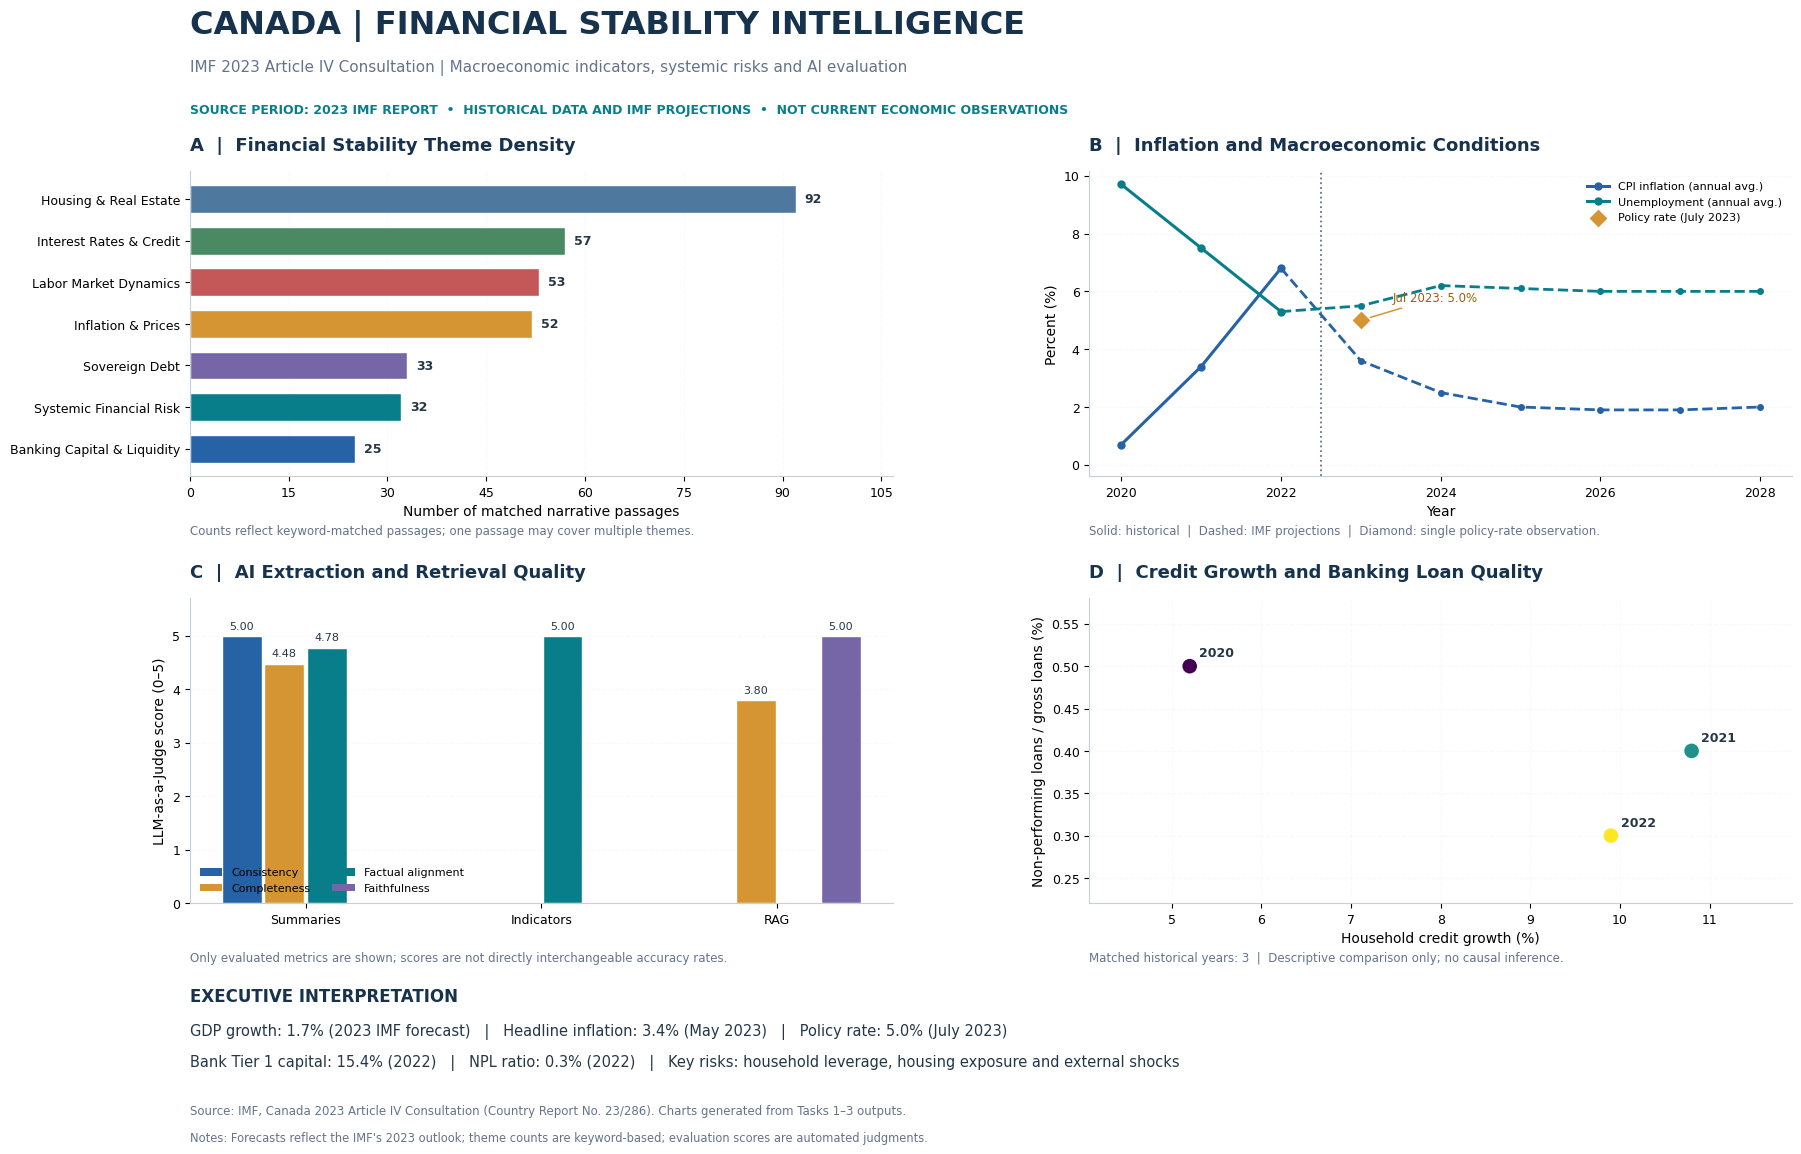


TASK 4 - FINAL VALIDATION
Dashboard panels: 4
pd.melt transformation: PASS
High-resolution export: PASS
PNG dimensions: (5861, 3789)
Export DPI: 320
Executive overlay: PASS
Historical/projected labels: PASS

SAVED DASHBOARD FILES
/content/Canada_IMF_Outputs/task4_dashboard/Canada_IMF_Executive_Dashboard.png
/content/Canada_IMF_Outputs/task4_dashboard/Canada_IMF_Executive_Dashboard.pdf
/content/Canada_IMF_Outputs/task4_dashboard/Canada_IMF_Executive_Dashboard.svg

PROJECT ARCHIVE
/content/Canada_Tasks1_4_Outputs.zip

TASK 4 COMPLETED SUCCESSFULLY


In [ ]:

# ============================================================
# TASK 4: FOUR-PANEL EXECUTIVE DASHBOARD
# Canada IMF 2023 Article IV Consultation
# High-resolution PNG + PDF + SVG
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch
import numpy as np
import json
import shutil
from pathlib import Path

# ---------- Professional visual styling ----------
NAVY = "#17324D"
BLUE = "#2563A6"
TEAL = "#087E8B"
GOLD = "#D59532"
PURPLE = "#7665A7"
RED = "#C45858"
GREY = "#64748B"
LIGHT = "#E7EDF3"
INK = "#253746"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#C5CFDA",
    "grid.alpha": 0.25,
    "savefig.dpi": 320
})

fig = plt.figure(figsize=(18, 12), facecolor="white")

gs = fig.add_gridspec(
    2, 2,
    left=0.075,
    right=0.965,
    top=0.84,
    bottom=0.23,
    wspace=0.28,
    hspace=0.40
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

# ---------- Dashboard heading ----------
fig.text(
    0.075, 0.955,
    "CANADA | FINANCIAL STABILITY INTELLIGENCE",
    fontsize=23,
    fontweight="bold",
    color=NAVY,
    ha="left"
)

fig.text(
    0.075, 0.923,
    "IMF 2023 Article IV Consultation | "
    "Macroeconomic indicators, systemic risks and AI evaluation",
    fontsize=11,
    color=GREY,
    ha="left"
)

fig.text(
    0.075, 0.888,
    "SOURCE PERIOD: 2023 IMF REPORT  •  "
    "HISTORICAL DATA AND IMF PROJECTIONS  •  "
    "NOT CURRENT ECONOMIC OBSERVATIONS",
    fontsize=9,
    fontweight="bold",
    color=TEAL
)

# ============================================================
# PANEL A - THEMATIC FINANCIAL STABILITY DISTRIBUTION
# ============================================================

theme_colors = [
    BLUE, TEAL, PURPLE, GOLD, RED, "#498A65", "#4E789D"
]

bars = ax1.barh(
    df_theme["theme"],
    df_theme["count"],
    color=theme_colors,
    height=0.67,
    edgecolor="white"
)

ax1.set_title(
    "A  |  Financial Stability Theme Density",
    loc="left",
    color=NAVY,
    pad=15
)

ax1.set_xlabel("Number of matched narrative passages")
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.grid(axis="x", linestyle="--", color=LIGHT)
ax1.set_axisbelow(True)

max_count = float(df_theme["count"].max())
ax1.set_xlim(0, max(1, max_count * 1.16))

for bar in bars:
    value = bar.get_width()
    ax1.text(
        value + max(0.3, max_count * 0.015),
        bar.get_y() + bar.get_height() / 2,
        f"{int(value)}",
        va="center",
        fontsize=9,
        color=INK,
        fontweight="bold"
    )

ax1.text(
    0, -0.19,
    "Counts reflect keyword-matched passages; "
    "one passage may cover multiple themes.",
    transform=ax1.transAxes,
    fontsize=8.5,
    color=GREY
)

# ============================================================
# PANEL B - LONGITUDINAL INFLATION AND FINANCIAL CONDITIONS
# ============================================================

series_plot = [
    (
        "cpi_inflation_annual_average_pct",
        "CPI inflation (annual avg.)",
        BLUE
    ),
    (
        "unemployment_annual_average_pct",
        "Unemployment (annual avg.)",
        TEAL
    )
]

for key, label, color in series_plot:
    data = df_long[
        df_long["indicator"] == key
    ].sort_values("year")

    historical = data[
        data["status"] != "projection"
    ]

    projected = data[
        data["status"] == "projection"
    ]

    if not historical.empty:
        ax2.plot(
            historical["year"],
            historical["value"],
            color=color,
            marker="o",
            linewidth=2.2,
            markersize=5,
            label=label
        )

    if not projected.empty:
        # Connect the projected path to the latest actual value.
        if not historical.empty:
            projected = pd.concat([
                historical.tail(1), projected
            ])

        ax2.plot(
            projected["year"],
            projected["value"],
            color=color,
            marker="o",
            linewidth=2,
            linestyle="--",
            markersize=4
        )

# Policy rate is a single July 2023 observation.
if policy_rate is not None:
    ax2.scatter(
        [2023], [policy_rate],
        color=GOLD,
        marker="D",
        s=105,
        edgecolors="white",
        linewidth=1.2,
        zorder=6,
        label="Policy rate (July 2023)"
    )

    ax2.annotate(
        f"Jul 2023: {policy_rate:.1f}%",
        xy=(2023, policy_rate),
        xytext=(2023.4, policy_rate + 0.65),
        fontsize=8.5,
        color="#99610F",
        arrowprops={
            "arrowstyle": "-",
            "color": GOLD,
            "lw": 1.1
        }
    )

ax2.axvline(
    2022.5,
    color=GREY,
    linestyle=":",
    linewidth=1.3
)

ax2.set_title(
    "B  |  Inflation and Macroeconomic Conditions",
    loc="left",
    color=NAVY,
    pad=15
)

ax2.set_xlabel("Year")
ax2.set_ylabel("Percent (%)")
ax2.set_xlim(2019.6, 2028.4)
ax2.set_ylim(
    bottom=min(-0.4, ax2.get_ylim()[0])
)
ax2.set_xticks(list(range(2020, 2029, 2)))

ax2.grid(axis="y", linestyle="--", color=LIGHT)
ax2.set_axisbelow(True)

ax2.legend(
    loc="upper right",
    fontsize=8,
    frameon=False
)

ax2.text(
    0, -0.19,
    "Solid: historical  |  Dashed: IMF projections  |  "
    "Diamond: single policy-rate observation.",
    transform=ax2.transAxes,
    fontsize=8.5,
    color=GREY
)

# ============================================================
# PANEL C - LLM EVALUATION AND MODEL DIAGNOSTICS
# ============================================================

evaluation_order = [
    "Task 1: Summaries",
    "Task 2: Indicators",
    "Task 3: RAG"
]

metric_order = [
    "Consistency",
    "Completeness",
    "Factual alignment",
    "Faithfulness"
]

metric_colors = {
    "Consistency": BLUE,
    "Completeness": GOLD,
    "Factual alignment": TEAL,
    "Faithfulness": PURPLE
}

x = np.arange(len(evaluation_order))
bar_width = 0.18

for j, metric in enumerate(metric_order):
    heights = []

    for evaluation in evaluation_order:
        subset = df_scores[
            (df_scores["evaluation"] == evaluation)
            & (df_scores["metric"] == metric)
        ]

        heights.append(
            float(subset["score"].iloc[0])
            if not subset.empty
            else np.nan
        )

    offsets = x + (j - 1.5) * bar_width

    for xpos, value in zip(offsets, heights):
        if np.isfinite(value):
            ax3.bar(
                xpos, value,
                width=bar_width * 0.94,
                color=metric_colors[metric],
                edgecolor="white"
            )

            ax3.text(
                xpos, value + 0.09,
                f"{value:.2f}",
                ha="center",
                va="bottom",
                fontsize=8,
                color=INK
            )

ax3.set_title(
    "C  |  AI Extraction and Retrieval Quality",
    loc="left",
    color=NAVY,
    pad=15
)

ax3.set_ylabel("LLM-as-a-Judge score (0–5)")
ax3.set_ylim(0, 5.7)
ax3.set_xticks(x)
ax3.set_xticklabels(
    ["Summaries", "Indicators", "RAG"]
)

ax3.grid(axis="y", linestyle="--", color=LIGHT)
ax3.set_axisbelow(True)

legend_handles = [
    Patch(
        facecolor=metric_colors[m],
        edgecolor="none",
        label=m
    )
    for m in metric_order
]

ax3.legend(
    handles=legend_handles,
    loc="lower left",
    fontsize=8,
    frameon=False,
    ncol=2
)

ax3.text(
    0, -0.19,
    "Only evaluated metrics are shown; "
    "scores are not directly interchangeable accuracy rates.",
    transform=ax3.transAxes,
    fontsize=8.5,
    color=GREY
)

# ============================================================
# PANEL D - HOUSEHOLD CREDIT GROWTH VS NPL RISK
# ============================================================

risk_x = df_risk["household_credit_growth_pct"].to_numpy()
risk_y = df_risk["npl_ratio_pct"].to_numpy()

ax4.scatter(
    risk_x, risk_y,
    s=140,
    c=range(len(df_risk)),
    cmap="viridis",
    edgecolors="white",
    linewidth=1.3,
    zorder=4
)

for _, row in df_risk.iterrows():
    ax4.annotate(
        str(int(row["year"])),
        (
            row["household_credit_growth_pct"],
            row["npl_ratio_pct"]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color=INK
    )

ax4.set_title(
    "D  |  Credit Growth and Banking Loan Quality",
    loc="left",
    color=NAVY,
    pad=15
)

ax4.set_xlabel("Household credit growth (%)")
ax4.set_ylabel("Non-performing loans / gross loans (%)")

ax4.grid(
    linestyle="--",
    color=LIGHT
)
ax4.set_axisbelow(True)

# Add sensible padding without distorting observed values.
x_pad = max(np.ptp(risk_x) * 0.2, 0.7)
y_pad = max(np.ptp(risk_y) * 0.25, 0.08)

ax4.set_xlim(
    float(np.min(risk_x)) - x_pad,
    float(np.max(risk_x)) + x_pad
)

ax4.set_ylim(
    max(0, float(np.min(risk_y)) - y_pad),
    float(np.max(risk_y)) + y_pad
)

ax4.text(
    0, -0.19,
    f"Matched historical years: {len(df_risk)}  |  "
    "Descriptive comparison only; no causal inference.",
    transform=ax4.transAxes,
    fontsize=8.5,
    color=GREY
)

# ============================================================
# EXECUTIVE INSIGHTS OVERLAY
# ============================================================

gdp = indicators.get("gdp_growth_forecast_pct")
inflation = indicators.get("headline_inflation_rate_pct")
tier1 = indicators.get("tier_1_capital_ratio")
npl_value = indicators.get("non_performing_loan_ratio")

def metric_text(value, suffix="%"):
    return (
        f"{float(value):.1f}{suffix}"
        if value is not None
        else "N/A"
    )

fig.text(
    0.075, 0.148,
    "EXECUTIVE INTERPRETATION",
    fontsize=12,
    color=NAVY,
    fontweight="bold"
)

executive_line_1 = (
    f"GDP growth: {metric_text(gdp)} (2023 IMF forecast)   |   "
    f"Headline inflation: {metric_text(inflation)} (May 2023)   |   "
    f"Policy rate: {metric_text(policy_rate)} (July 2023)"
)

executive_line_2 = (
    f"Bank Tier 1 capital: {metric_text(tier1)} (2022)   |   "
    f"NPL ratio: {metric_text(npl_value)} (2022)   |   "
    "Key risks: household leverage, housing exposure and external shocks"
)

fig.text(
    0.075, 0.120,
    executive_line_1,
    fontsize=10.5,
    color=INK
)

fig.text(
    0.075, 0.094,
    executive_line_2,
    fontsize=10.5,
    color=INK
)

fig.text(
    0.075, 0.054,
    "Source: IMF, Canada 2023 Article IV Consultation "
    "(Country Report No. 23/286). "
    "Charts generated from Tasks 1–3 outputs.",
    fontsize=8.5,
    color=GREY
)

fig.text(
    0.075, 0.032,
    "Notes: Forecasts reflect the IMF's 2023 outlook; "
    "theme counts are keyword-based; "
    "evaluation scores are automated judgments.",
    fontsize=8.3,
    color=GREY
)

# ---------- Save high-resolution outputs ----------
png_path = DASH / "Canada_IMF_Executive_Dashboard.png"
pdf_path = DASH / "Canada_IMF_Executive_Dashboard.pdf"
svg_path = DASH / "Canada_IMF_Executive_Dashboard.svg"

fig.savefig(
    png_path,
    dpi=320,
    bbox_inches="tight",
    pad_inches=0.25
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.25
)

fig.savefig(
    svg_path,
    bbox_inches="tight",
    pad_inches=0.25
)

plt.show()
plt.close(fig)

# ---------- Validate generated figures ----------
from PIL import Image

with Image.open(png_path) as im:
    image_dimensions = im.size

assert all(
    p.exists() and p.stat().st_size > 0
    for p in [png_path, pdf_path, svg_path]
)

assert image_dimensions[0] >= 4000
assert image_dimensions[1] >= 2500

# ---------- Save final dashboard metadata ----------
dashboard_validation = {
    "country": "Canada",
    "report_year": 2023,
    "plot_count": 4,
    "panel_names": [
        "Seven-theme financial stability distribution",
        "Inflation and macroeconomic trends",
        "LLM evaluation diagnostics",
        "Household credit growth versus NPL"
    ],
    "tidy_transformation": "pd.melt",
    "dpi": 320,
    "image_dimensions": list(image_dimensions),
    "historical_projection_distinction": True,
    "single_policy_rate_point": True,
    "matched_risk_observations": len(df_risk),
    "executive_overlay": True,
    "png_exists": png_path.exists(),
    "pdf_exists": pdf_path.exists(),
    "svg_exists": svg_path.exists(),
    "task4_complete": True
}

(DASH / "task4_validation.json").write_text(
    json.dumps(dashboard_validation, indent=2),
    encoding="utf-8"
)

# ---------- Archive combined project outputs ----------
archive_path = shutil.make_archive(
    "/content/Canada_Tasks1_4_Outputs",
    "zip",
    root_dir=OUT
)

print("\n" + "=" * 70)
print("TASK 4 - FINAL VALIDATION")
print("=" * 70)

print("Dashboard panels:", 4)
print("pd.melt transformation: PASS")
print("High-resolution export: PASS")
print("PNG dimensions:", image_dimensions)
print("Export DPI:", 320)
print("Executive overlay: PASS")
print("Historical/projected labels: PASS")

print("\nSAVED DASHBOARD FILES")
print(png_path)
print(pdf_path)
print(svg_path)

print("\nPROJECT ARCHIVE")
print(archive_path)

print("\nTASK 4 COMPLETED SUCCESSFULLY")


In [ ]:

# ============================================================
# BONUS: MULTI-QUERY RAG RETRIEVAL AND GENERATION
# Canada IMF 2023 | Reuses Task 3 FAISS index and embeddings
# ============================================================

import json, re, hashlib, time
from pathlib import Path
import numpy as np
from google.genai import types, errors

BONUS_DIR = OUT / "task5_multiquery"
BONUS_DIR.mkdir(parents=True, exist_ok=True)

# Preserve the original Task 3 baseline.
baseline_answers = load_json("task3_rag_answers.json", {})
baseline_judge = load_json("task3_rag_evaluation.json", {})
baseline_retrieval = load_json("task3_retrieval_results.json", [])

assert baseline_answers.get("status") == "complete"
assert baseline_judge.get("status") == "complete"
assert len(baseline_retrieval) == 5
assert len(RAG_QUESTIONS) == 5
assert index.ntotal == len(vector_metadata)

def bonus_save(filename, obj):
    path = BONUS_DIR / filename
    tmp = path.with_suffix(".tmp")
    tmp.write_text(
        json.dumps(obj, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )
    tmp.replace(path)

def bonus_load(filename, default=None):
    path = BONUS_DIR / filename
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    return default

# ---------- 1. Generate multiple query variants in Python ----------
# These are reformulations, not preselected document passages.

QUERY_CONCEPTS = {
    "Q1": [
        "capital requirements liquidity buffers smaller banks",
        "small and medium sized bank regulatory safeguards",
        "domestic stability buffer bank supervision recommendations"
    ],
    "Q2": [
        "mortgage repricing 2023 2025 higher interest rates",
        "household debt servicing mortgage renewal vulnerabilities",
        "residential mortgage exposure stress scenario safeguards"
    ],
    "Q3": [
        "inflation 2 percent target end 2024 forecast",
        "headline core inflation disinflation timeline",
        "Bank of Canada inflation outlook restrictive policy"
    ],
    "Q4": [
        "nonbank financial institutions stress testing regulators",
        "NBFI pension funds asset managers data gaps",
        "nonbank supervisory information powers liquidity risks"
    ],
    "Q5": [
        "downside economic risks recession Canada",
        "financial instability inflation expectations household leverage",
        "global banking contagion external shocks vulnerabilities"
    ]
}

def generate_query_variants(question_id, question):
    concepts = QUERY_CONCEPTS[question_id]
    return list(dict.fromkeys([
        question,
        f"Canada IMF 2023 {concepts[0]}",
        f"IMF policy assessment {concepts[1]}",
        f"Canada financial stability {concepts[2]}"
    ]))

# ---------- 2. Build exact dense FAISS candidate retrieval ----------
def search_variants(variants, per_query=10):
    q_vectors = embedder.encode_query(
        variants,
        convert_to_numpy=True,
        normalize_embeddings=True
    )
    q_vectors = np.ascontiguousarray(
        q_vectors, dtype=np.float32
    )

    distances, positions = index.search(
        q_vectors, min(per_query, index.ntotal)
    )

    # Reciprocal Rank Fusion gives documents credit for
    # appearing across independent query formulations.
    scores = {}
    matched_queries = {}

    for query_no, ranked_positions in enumerate(positions):
        for rank, position in enumerate(ranked_positions, start=1):
            if position < 0:
                continue

            pos = int(position)
            scores[pos] = scores.get(pos, 0.0) + 1 / (60 + rank)
            matched_queries.setdefault(pos, set()).add(query_no)

    return scores, matched_queries

# ---------- 3. Context expansion and diversification ----------
def build_enhanced_evidence(question_id, question, top_n=7):
    variants = generate_query_variants(question_id, question)
    scores, matched = search_variants(variants, per_query=12)

    ranked = sorted(
        scores,
        key=lambda pos: scores[pos],
        reverse=True
    )

    # Keep distinct parent chunks instead of repetitive windows.
    selected = []
    seen_parents = set()

    for pos in ranked:
        item = vector_metadata[pos]
        parent = item["parent_chunk_id"]

        if parent in seen_parents:
            continue

        selected.append((pos, scores[pos], matched[pos]))
        seen_parents.add(parent)

        if len(selected) == top_n:
            break

    results = []

    for pos, score, matched_queries in selected:
        item = vector_metadata[pos]

        # Expand within the original parent chunk to preserve
        # sentences that may have crossed an embedding window.
        parent = next(
            c for c in rag_chunks
            if c["chunk_id"] == item["parent_chunk_id"]
        )

        results.append({
            "evidence_id": f"E{len(results) + 1}",
            "window_id": item["window_id"],
            "parent_chunk_id": parent["chunk_id"],
            "section": parent["section_title"],
            "pdf_page_range": [
                parent["start_page"],
                parent["end_page"]
            ],
            "fusion_score": round(float(score), 6),
            "matched_query_count": len(matched_queries),
            "text": parent["text"]
        })

    return {
        "question_id": question_id,
        "question": question,
        "query_variants": variants,
        "retrieved_evidence": results
    }

enhanced_retrieval = [
    build_enhanced_evidence(q["id"], q["question"])
    for q in RAG_QUESTIONS
]

bonus_save("multiquery_retrieval.json", enhanced_retrieval)

print("MULTI-QUERY RETRIEVAL RESULTS")
for record in enhanced_retrieval:
    print(
        record["question_id"],
        "| queries:", len(record["query_variants"]),
        "| evidence:", len(record["retrieved_evidence"])
    )
    for hit in record["retrieved_evidence"][:3]:
        print(" ", hit["evidence_id"], hit["section"])

# ---------- 4. Construct grounded evidence bundle ----------
def bonus_evidence_bundle(records):
    blocks = []

    for record in records:
        lines = [
            f"{record['question_id']}: {record['question']}"
        ]

        for hit in record["retrieved_evidence"]:
            lines.append(
                f"[{hit['evidence_id']}] "
                f"Section: {hit['section']}; "
                f"PDF pages: {hit['pdf_page_range']}\n"
                f"{hit['text']}"
            )

        blocks.append("\n\n".join(lines))

    return "\n\n========== NEXT QUESTION ==========\n\n".join(blocks)

multi_evidence_text = bonus_evidence_bundle(enhanced_retrieval)

# Reuse the structured JSON schema from Task 3.
MULTI_ANSWER_SCHEMA = ANSWER_SCHEMA

MULTI_SYSTEM = """
You are an evidence-grounded IMF research assistant.

Answer five questions about Canada's 2023 Article IV Consultation.

Rules:
1. Use ONLY evidence retrieved for the corresponding question.
2. Cite the evidence IDs E1, E2, etc., for that question.
3. Do not invent statistics or recommendations.
4. Retain the original report's 2023 perspective.
5. Explain specific findings rather than giving generic answers.
6. If genuinely insufficient, explicitly abstain.
7. Distinguish risks, mitigating factors, and policy advice.
8. Return one answer each for Q1-Q5 in valid JSON.
"""

MULTI_PROMPT = f"""
Answer Q1-Q5 using the expanded Multi-Query FAISS evidence.

For every question, provide:
- A concise, factual response (approximately 60-110 words).
- One or more valid evidence IDs when evidence is sufficient.
- A boolean sufficient_evidence flag.

Do not cite evidence belonging to another question.
Do not invent information absent from the retrieved passages.

EVIDENCE:
{multi_evidence_text}
"""

# ---------- 5. Use existing quota-aware Gemini helper ----------
# Defined in Task 3 Cell 11.
existing = bonus_load("multiquery_answers.json", {})

def validate_multi_answers(items):
    if not isinstance(items, list) or len(items) != 5:
        return False

    by_id = {x.get("question_id"): x for x in items}

    if set(by_id) != {q["id"] for q in RAG_QUESTIONS}:
        return False

    for record in enhanced_retrieval:
        item = by_id[record["question_id"]]
        allowed = {
            h["evidence_id"] for h in record["retrieved_evidence"]
        }

        if not isinstance(item.get("answer"), str):
            return False

        if type(item.get("sufficient_evidence")) is not bool:
            return False

        cited = item.get("citations", [])
        if not isinstance(cited, list):
            return False

        if any(c not in allowed for c in cited):
            return False

        if item["sufficient_evidence"] and not cited:
            return False

    return True

if (
    existing.get("status") == "complete"
    and validate_multi_answers(existing.get("answers", []))
):
    enhanced_answers = existing
    print("\nReusing completed Multi-Query answers.")

else:
    # Cache key includes the full prompt and model configuration.
    generated = rag_gemini_call(
        EXTRACT_MODEL,
        MULTI_SYSTEM,
        MULTI_PROMPT,
        MULTI_ANSWER_SCHEMA,
        "multiquery_bonus_answers"
    )

    if (
        isinstance(generated, dict)
        and validate_multi_answers(generated.get("answers", []))
    ):
        enhanced_answers = {
            "status": "complete",
            "model": EXTRACT_MODEL,
            "method": "Multi-Query FAISS + Reciprocal Rank Fusion",
            "answers": generated["answers"]
        }
    else:
        enhanced_answers = {
            "status": "pending_or_invalid",
            "model": EXTRACT_MODEL,
            "answers": [],
            "note": "No fabricated answers; retry when API is available."
        }

    bonus_save("multiquery_answers.json", enhanced_answers)

# ---------- 6. Display ----------
print("\n" + "=" * 65)
print("MULTI-QUERY RAG ANSWER GENERATION")
print("=" * 65)

print("Status:", enhanced_answers["status"])

if enhanced_answers["status"] == "complete":
    for item in sorted(
        enhanced_answers["answers"],
        key=lambda x: x["question_id"]
    ):
        print(f"\n{item['question_id']}: {item['answer']}")
        print("Citations:", item["citations"])
        print("Evidence sufficient:", item["sufficient_evidence"])

print("\nCELL 14 COMPLETED")


MULTI-QUERY RETRIEVAL RESULTS
Q1 | queries: 4 | evidence: 7
  E1 Policy B - Safeguarding Financial Stability
  E2 Recent Developments
  E3 Staff Appraisal
Q2 | queries: 4 | evidence: 7
  E1 Annex V - FSAP Recommendations
  E2 Annex V - FSAP Recommendations
  E3 Outlook and Risks
Q3 | queries: 4 | evidence: 7
  E1 Outlook and Risks
  E2 Press Release
  E3 Key Issues
Q4 | queries: 4 | evidence: 7
  E1 Policy B - Safeguarding Financial Stability
  E2 Staff Appraisal
  E3 Outlook and Risks
Q5 | queries: 4 | evidence: 7
  E1 Press Release
  E2 Annex II - External Sector Assessment
  E3 Key Issues

MULTI-QUERY RAG ANSWER GENERATION
Status: complete

Q1: The IMF suggests that while deposit insurance is generally adequate, there is scope to further protect depositors at small banks. Given global banking sector uncertainties, the IMF recommends considering the extension of the Domestic Stability Buffer—currently applied to larger banks—to small and medium-sized banks (SMSBs). Additionally, fede

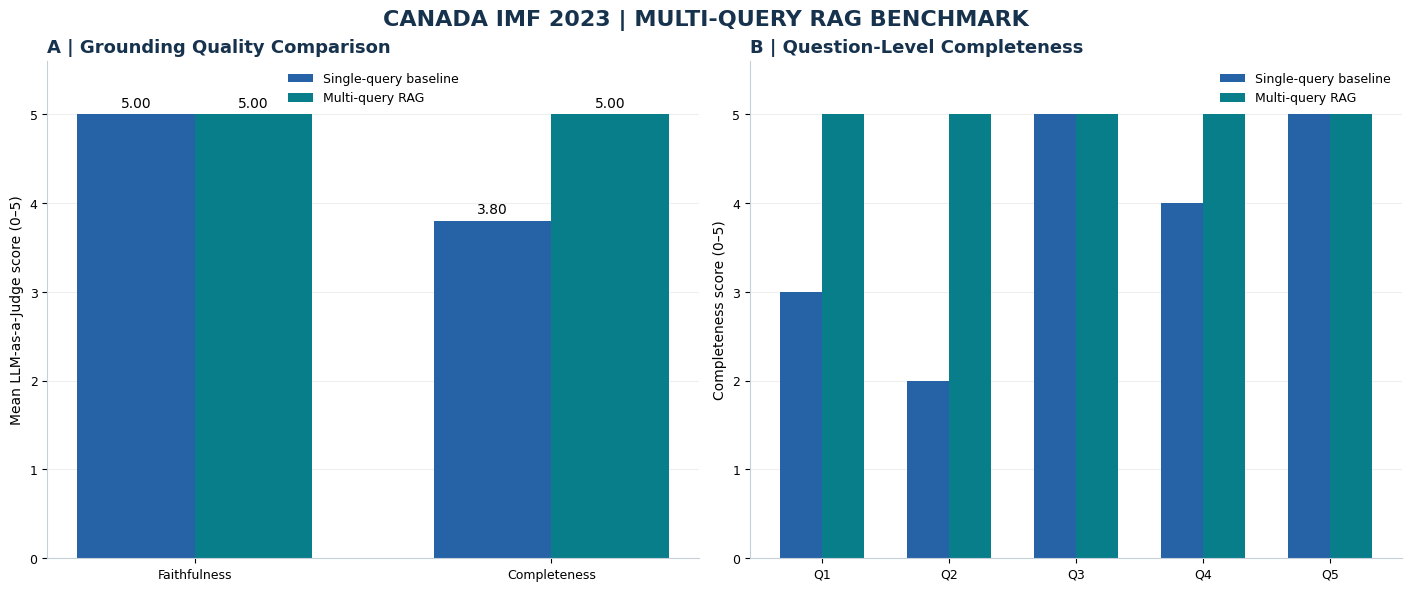


BONUS EXTENSION - FINAL RESULTS

BASELINE VS MULTI-QUERY
question_id  baseline_faithfulness  enhanced_faithfulness  baseline_completeness  enhanced_completeness
         Q1                      5                      5                      3                      5
         Q2                      5                      5                      2                      5
         Q3                      5                      5                      5                      5
         Q4                      5                      5                      4                      5
         Q5                      5                      5                      5                      5

AGGREGATE METRICS
{
  "baseline": {
    "faithfulness": 5.0,
    "completeness": 3.8,
    "substantive_answers": 3
  },
  "multiquery": {
    "faithfulness": 5.0,
    "completeness": 5.0,
    "substantive_answers": 5
  },
  "improvement": {
    "faithfulness": 0.0,
    "completeness": 1.2,
    "substantive_answers":

In [ ]:

# ============================================================
# MULTI-QUERY RAG COMPARATIVE EVALUATION
# Baseline vs Enhanced | Judge audit | High-resolution figures
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil
from pathlib import Path

# ---------- 1. Validate required outputs ----------
baseline_judge = load_json("task3_rag_evaluation.json", {})
baseline_answers = load_json("task3_rag_answers.json", {})
enhanced_answers = bonus_load("multiquery_answers.json", {})

assert baseline_judge.get("status") == "complete"
assert baseline_answers.get("status") == "complete"

if enhanced_answers.get("status") != "complete":
    print(
        "Enhanced answers are pending. Run Cell 14 again "
        "when the Gemini API is available."
    )
    raise RuntimeError("Multi-Query generation not yet complete.")

# ---------- 2. Independent evaluator ----------
BONUS_JUDGE_SCHEMA = {
    "type": "object",
    "properties": {
        "evaluations": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "question_id": {"type": "string"},
                    "faithfulness": {
                        "type": "integer",
                        "minimum": 0,
                        "maximum": 5
                    },
                    "completeness": {
                        "type": "integer",
                        "minimum": 0,
                        "maximum": 5
                    },
                    "explanation": {"type": "string"}
                },
                "required": [
                    "question_id", "faithfulness",
                    "completeness", "explanation"
                ],
                "additionalProperties": False
            }
        }
    },
    "required": ["evaluations"],
    "additionalProperties": False
}

BONUS_JUDGE_SYSTEM = """
You are an independent evaluator of source-grounded IMF RAG.

Evaluate the five enhanced answers only against the supplied
retrieved evidence.

Faithfulness (0-5):
Whether every material factual statement is supported.
Penalize invented claims, wrong figures and wrong periods.

Completeness (0-5):
Whether the answer covers the essential information
needed to address its question.

If the model abstains, assess whether the evidence actually
was insufficient. Do not award high completeness to an
unnecessary abstention.

Do not award automatic perfect scores.
Give evidence-based explanations and use the same
0-5 criteria applied to the baseline.
"""

BONUS_JUDGE_PROMPT = (
    "ENHANCED RAG SOURCE EVIDENCE:\n"
    + multi_evidence_text
    + "\n\nENHANCED ANSWERS:\n"
    + json.dumps(
        enhanced_answers["answers"],
        indent=2, ensure_ascii=False
    )
    + "\n\nEvaluate Q1-Q5 independently."
)

previous_audit = bonus_load("multiquery_evaluation.json", {})

if previous_audit.get("status") == "complete":
    enhanced_audit = previous_audit

else:
    generated_judge = rag_gemini_call(
        JUDGE_MODEL,
        BONUS_JUDGE_SYSTEM,
        BONUS_JUDGE_PROMPT,
        BONUS_JUDGE_SCHEMA,
        "multiquery_bonus_judge"
    )

    valid = (
        isinstance(generated_judge, dict)
        and isinstance(generated_judge.get("evaluations"), list)
        and len(generated_judge["evaluations"]) == 5
    )

    if valid:
        items = generated_judge["evaluations"]
        ids = [x.get("question_id") for x in items]

        valid = (
            len(set(ids)) == 5
            and set(ids) == {q["id"] for q in RAG_QUESTIONS}
            and all(
                type(x.get("faithfulness")) is int
                and 0 <= x["faithfulness"] <= 5
                and type(x.get("completeness")) is int
                and 0 <= x["completeness"] <= 5
                and isinstance(x.get("explanation"), str)
                for x in items
            )
        )

    if valid:
        enhanced_audit = {
            "status": "complete",
            "model": JUDGE_MODEL,
            "evaluations": generated_judge["evaluations"],
            "mean_faithfulness": round(
                np.mean([
                    x["faithfulness"] for x in items
                ]), 2
            ),
            "mean_completeness": round(
                np.mean([
                    x["completeness"] for x in items
                ]), 2
            )
        }
    else:
        enhanced_audit = {
            "status": "pending_or_invalid",
            "evaluations": []
        }

    bonus_save("multiquery_evaluation.json", enhanced_audit)

if enhanced_audit["status"] != "complete":
    print("Gemini judge is pending; all enhanced answers are saved.")
    raise RuntimeError(
        "Bonus comparison awaits a valid judge evaluation."
    )

# ---------- 3. Build paired baseline-enhanced comparison ----------
baseline_scores = {
    item["question_id"]: item
    for item in baseline_judge["evaluations"]
}

enhanced_scores = {
    item["question_id"]: item
    for item in enhanced_audit["evaluations"]
}

baseline_answer_map = {
    item["question_id"]: item
    for item in baseline_answers["answers"]
}

enhanced_answer_map = {
    item["question_id"]: item
    for item in enhanced_answers["answers"]
}

comparison_rows = []

for question in RAG_QUESTIONS:
    qid = question["id"]
    before = baseline_scores[qid]
    after = enhanced_scores[qid]

    comparison_rows.append({
        "question_id": qid,
        "question": question["question"],
        "baseline_faithfulness": before["faithfulness"],
        "enhanced_faithfulness": after["faithfulness"],
        "baseline_completeness": before["completeness"],
        "enhanced_completeness": after["completeness"],
        "delta_faithfulness": (
            after["faithfulness"] - before["faithfulness"]
        ),
        "delta_completeness": (
            after["completeness"] - before["completeness"]
        ),
        "baseline_answered": bool(
            baseline_answer_map[qid]["sufficient_evidence"]
        ),
        "enhanced_answered": bool(
            enhanced_answer_map[qid]["sufficient_evidence"]
        )
    })

df_compare = pd.DataFrame(comparison_rows)

df_compare.to_csv(
    BONUS_DIR / "baseline_multiquery_comparison.csv",
    index=False
)

# ---------- 4. Aggregate performance metrics ----------
baseline_faith = float(
    baseline_judge["mean_faithfulness"]
)
baseline_complete = float(
    baseline_judge["mean_completeness"]
)

enhanced_faith = float(
    enhanced_audit["mean_faithfulness"]
)
enhanced_complete = float(
    enhanced_audit["mean_completeness"]
)

baseline_answered = int(
    df_compare["baseline_answered"].sum()
)
enhanced_answered = int(
    df_compare["enhanced_answered"].sum()
)

metrics = {
    "baseline": {
        "faithfulness": baseline_faith,
        "completeness": baseline_complete,
        "substantive_answers": baseline_answered
    },
    "multiquery": {
        "faithfulness": enhanced_faith,
        "completeness": enhanced_complete,
        "substantive_answers": enhanced_answered
    },
    "improvement": {
        "faithfulness": round(
            enhanced_faith - baseline_faith, 2
        ),
        "completeness": round(
            enhanced_complete - baseline_complete, 2
        ),
        "substantive_answers": (
            enhanced_answered - baseline_answered
        )
    }
}

bonus_save("bonus_comparison_metrics.json", metrics)

# ---------- 5. High-resolution comparison chart ----------
fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.8),
    constrained_layout=True
)

NAVY = "#17324D"
BLUE = "#2563A6"
TEAL = "#087E8B"
GOLD = "#D59532"

# Left: Mean judge scores
labels = ["Faithfulness", "Completeness"]
baseline_values = [baseline_faith, baseline_complete]
enhanced_values = [enhanced_faith, enhanced_complete]

x = np.arange(2)
width = 0.33

axes[0].bar(
    x - width / 2,
    baseline_values,
    width,
    color=BLUE,
    label="Single-query baseline"
)
axes[0].bar(
    x + width / 2,
    enhanced_values,
    width,
    color=TEAL,
    label="Multi-query RAG"
)

for i in range(2):
    axes[0].text(
        x[i] - width / 2,
        baseline_values[i] + 0.08,
        f"{baseline_values[i]:.2f}",
        ha="center", fontsize=10
    )
    axes[0].text(
        x[i] + width / 2,
        enhanced_values[i] + 0.08,
        f"{enhanced_values[i]:.2f}",
        ha="center", fontsize=10
    )

axes[0].set_xticks(x, labels)
axes[0].set_ylim(0, 5.6)
axes[0].set_ylabel("Mean LLM-as-a-Judge score (0–5)")
axes[0].set_title(
    "A | Grounding Quality Comparison",
    loc="left", color=NAVY, fontweight="bold"
)
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)

# Right: Question-level completeness
questions = df_compare["question_id"].tolist()
positions = np.arange(len(questions))

axes[1].bar(
    positions - width / 2,
    df_compare["baseline_completeness"],
    width,
    color=BLUE,
    label="Single-query baseline"
)

axes[1].bar(
    positions + width / 2,
    df_compare["enhanced_completeness"],
    width,
    color=TEAL,
    label="Multi-query RAG"
)

axes[1].set_xticks(positions, questions)
axes[1].set_ylim(0, 5.6)
axes[1].set_ylabel("Completeness score (0–5)")
axes[1].set_title(
    "B | Question-Level Completeness",
    loc="left", color=NAVY, fontweight="bold"
)
axes[1].legend(frameon=False, fontsize=9)
axes[1].grid(axis="y", alpha=0.2)
axes[1].set_axisbelow(True)

fig.suptitle(
    "CANADA IMF 2023 | MULTI-QUERY RAG BENCHMARK",
    fontsize=16,
    fontweight="bold",
    color=NAVY
)

fig.savefig(
    BONUS_DIR / "MultiQuery_RAG_Comparison.png",
    dpi=320,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    BONUS_DIR / "MultiQuery_RAG_Comparison.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ---------- 6. Final reproducibility checks ----------
validation = {
    "country": "Canada",
    "report_year": 2023,
    "extension": "Enhanced Multi-Query RAG",
    "baseline_retrieval": "Single-query local FAISS",
    "enhanced_retrieval": (
        "Four Python query variants per question "
        "with Reciprocal Rank Fusion"
    ),
    "question_count": 5,
    "original_baseline_preserved": True,
    "enhanced_answers_complete": True,
    "enhanced_judge_complete": True,
    "comparison_valid": (
        len(df_compare) == 5
        and df_compare["question_id"].nunique() == 5
    ),
    "metrics": metrics,
    "bonus_extension_complete": True
}

bonus_save("bonus_validation.json", validation)

# ---------- 7. Archive all Tasks 1-4 plus bonus ----------
archive = shutil.make_archive(
    "/content/Canada_IMF_Final_All_Tasks",
    "zip",
    root_dir=OUT
)

print("\n" + "=" * 70)
print("BONUS EXTENSION - FINAL RESULTS")
print("=" * 70)

print("\nBASELINE VS MULTI-QUERY")
print(df_compare[
    [
        "question_id",
        "baseline_faithfulness",
        "enhanced_faithfulness",
        "baseline_completeness",
        "enhanced_completeness"
    ]
].to_string(index=False))

print("\nAGGREGATE METRICS")
print(json.dumps(metrics, indent=2))

print("\nVALIDATION")
print("Five paired questions:", len(df_compare))
print("Comparison valid:", validation["comparison_valid"])
print("Extension complete:", validation["bonus_extension_complete"])

print("\nFINAL ARCHIVE:", archive)
print("\nBONUS EXTENSION COMPLETED SUCCESSFULLY")
